In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()


Saving Nassau Candy Distributor.csv to Nassau Candy Distributor.csv


In [2]:
import io

file_name = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset loaded successfully!
Dataset shape: (10194, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Sales,Units,Gross Profit,Cost,Lead Time,Profit Margin,Cost Per Unit,Sales Per Unit,Profit Per Unit,Order Year
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,...,6.50,2,4.22,2.28,909,64.923077,1.14,3.25,2.11,2024
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,7.50,2,4.90,2.60,909,65.333333,1.30,3.75,2.45,2024
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,10.47,3,7.47,3.00,909,71.346705,1.00,3.49,2.49,2024
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,10.80,3,7.50,3.30,909,69.444444,1.10,3.60,2.50,2024
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,11.25,3,7.35,3.90,912,65.333333,1.30,3.75,2.45,2024



Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Lead Time', 'Profit Margin', 'Cost Per Unit', 'Sales Per Unit', 'Profit Per Unit', 'Order Year']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 24 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Row ID           10194 non-null  int64  
 1   Order ID         10194 non-null  object 
 2   Order Date       10194 non-null  object 
 3   Ship Date        10194 non-null  object 
 4   Ship Mode        10194 non-null  object 
 5   Customer ID      10194 non-null  int64  
 6   Country/Region   10194 non-null  object 
 7   City             10194 non-null  object 
 8   State/Province   10194 non-null  object 
 9   Postal Code   

In [3]:
print("Missing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDate columns:")
for col in ["Order Date", "Ship Date"]:
    if col in df.columns:
        print(col, df[col].head().tolist())

print("\nNumeric summary:")
display(df.describe(include="all").T)


Missing values:


,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Country/Region,0
City,0
State/Province,0
Postal Code,0



Duplicate rows: 0

Date columns:
Order Date ['03-01-2024', '04-01-2024', '04-01-2024', '04-01-2024', '05-01-2024']
Ship Date ['30-06-2026', '01-07-2026', '01-07-2026', '01-07-2026', '05-07-2026']

Numeric summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,10194.0,NaN,NaN,NaN,5097.5,2942.898656,1.0,2549.25,5097.5,7645.75,10194.0
Order ID,10194,8549,US-2022-130974-CHO-SCR-58000,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,10194,717,02-09-2025,62,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,10194,1338,07-06-2028,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,10194,4,Standard Class,6120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,10194.0,NaN,NaN,NaN,134468.961154,20231.483007,100006.0,117212.0,133550.0,152051.0,192314.0
Country/Region,10194,2,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,10194,542,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State/Province,10194,59,California,2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Postal Code,10194,654,10035,263,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Step 3.1: Standardize column names

df.columns = df.columns.str.strip()

print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("\nAvailable columns:")
print(df.columns.tolist())

required_columns = [
    "Order ID", "Order Date", "Ship Date",
    "Ship Mode", "Region", "Product Name",
    "Sales", "Units", "Gross Profit", "Cost"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

print("\nRequired columns missing:", missing_columns)


Total rows: 10194
Total columns: 24

Available columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Lead Time', 'Profit Margin', 'Cost Per Unit', 'Sales Per Unit', 'Profit Per Unit', 'Order Year']

Required columns missing: []


In [5]:
# Step 3.2: Convert data types

for col in ["Order Date", "Ship Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

numeric_columns = ["Sales", "Units", "Gross Profit", "Cost"]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[[
    col for col in ["Order Date", "Ship Date",
                    "Sales", "Units", "Gross Profit", "Cost"]
    if col in df.columns
]].dtypes)

display(df.head())


Order Date      datetime64[ns]
Ship Date       datetime64[ns]
Sales                  float64
Units                    int64
Gross Profit           float64
Cost                   float64
dtype: object


/tmp/ipykernel_618/589151135.py:5: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df[col] = pd.to_datetime(df[col], errors="coerce")


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Sales,Units,Gross Profit,Cost,Lead Time,Profit Margin,Cost Per Unit,Sales Per Unit,Profit Per Unit,Order Year
0,1,US-2021-103800-CHO-MIL-31000,2024-03-01,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,6.50,2,4.22,2.28,909,64.923077,1.14,3.25,2.11,2024
1,2,US-2021-112326-CHO-TRI-54000,2024-04-01,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,7.50,2,4.90,2.60,909,65.333333,1.30,3.75,2.45,2024
2,3,US-2021-112326-CHO-NUT-13000,2024-04-01,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,10.47,3,7.47,3.00,909,71.346705,1.00,3.49,2.49,2024
3,4,US-2021-112326-CHO-SCR-58000,2024-04-01,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,10.80,3,7.50,3.30,909,69.444444,1.10,3.60,2.50,2024
4,5,US-2021-141817-CHO-TRI-54000,2024-05-01,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,11.25,3,7.35,3.90,912,65.333333,1.30,3.75,2.45,2024


In [6]:
# Step 3.3: Calculate shipping lead time

if {"Order Date", "Ship Date"}.issubset(df.columns):
    df["Lead Time Days"] = (
        df["Ship Date"] - df["Order Date"]
    ).dt.days

    print("Missing lead times:",
          df["Lead Time Days"].isna().sum())

    print("Negative lead times:",
          (df["Lead Time Days"] < 0).sum())

    print("\nLead-time summary:")
    display(df["Lead Time Days"].describe())

    print("\nLead times below zero:")
    display(df.loc[
        df["Lead Time Days"] < 0,
        ["Order ID", "Order Date", "Ship Date", "Lead Time Days"]
    ].head(10))

    print("\nLead times above 60 days:")
    display(df.loc[
        df["Lead Time Days"] > 60,
        ["Order ID", "Order Date", "Ship Date", "Lead Time Days"]
    ].head(10))


Missing lead times: 6064
Negative lead times: 0

Lead-time summary:


,Lead Time Days
count,4130.000000
mean,1366.009685
std,302.829972
min,613.000000
25%,1155.000000
50%,1361.000000
75%,1598.000000
max,1965.000000



Lead times below zero:


,Order ID,Order Date,Ship Date,Lead Time Days



Lead times above 60 days:


,Order ID,Order Date,Ship Date,Lead Time Days
0,US-2021-103800-CHO-MIL-31000,2024-03-01,2026-06-30,851.0
1,US-2021-112326-CHO-TRI-54000,2024-04-01,2026-07-01,821.0
2,US-2021-112326-CHO-NUT-13000,2024-04-01,2026-07-01,821.0
3,US-2021-112326-CHO-SCR-58000,2024-04-01,2026-07-01,821.0
4,US-2021-141817-CHO-TRI-54000,2024-05-01,2026-07-05,795.0
5,US-2021-167199-CHO-SCR-58000,2024-06-01,2026-07-03,762.0
6,US-2021-167199-CHO-TRI-54000,2024-06-01,2026-07-03,762.0
7,US-2021-106054-CHO-MIL-31000,2024-06-01,2026-06-30,759.0
8,US-2021-167199-CHO-NUT-13000,2024-06-01,2026-07-03,762.0
9,US-2021-167199-CHO-MIL-31000,2024-06-01,2026-07-03,762.0


In [7]:
# Step 3.4: Data quality report

print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values by column:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Count")
)

print("\nPercentage of missing values:")
display(
    (df.isnull().mean() * 100)
      .round(2)
      .to_frame("Missing Percentage")
)


Duplicate rows: 0

Missing values by column:


,Missing Count
Order Date,6064
Lead Time Days,6064
Row ID,0
Ship Date,0
Order ID,0
Customer ID,0
Country/Region,0
City,0
Ship Mode,0
State/Province,0



Percentage of missing values:


,Missing Percentage
Row ID,0.00
Order ID,0.00
Order Date,59.49
Ship Date,0.00
Ship Mode,0.00
Customer ID,0.00
Country/Region,0.00
City,0.00
State/Province,0.00
Postal Code,0.00


In [8]:
# Step 4.1: Reload the original dates as text

import pandas as pd
import io

raw_df = pd.read_csv(
    io.BytesIO(uploaded[file_name]),
    dtype=str
)

print("Original date examples:")

for col in ["Order Date", "Ship Date"]:
    print(f"\n{col}:")
    display(raw_df[col].head(15))

    print("\nMost common original date values:")
    display(raw_df[col].value_counts(dropna=False).head(10))

print("\nOriginal date fields:")
display(raw_df[["Order Date", "Ship Date"]].sample(
    min(15, len(raw_df)), random_state=42
))


Original date examples:

Order Date:


,Order Date
0,03-01-2024
1,04-01-2024
2,04-01-2024
3,04-01-2024
4,05-01-2024
5,06-01-2024
6,06-01-2024
7,06-01-2024
8,06-01-2024
9,06-01-2024



Most common original date values:


,count
Order Date,
02-09-2025,62
01-12-2025,57
02-12-2025,57
09-12-2025,54
24-11-2025,52
10-11-2025,50
11-12-2025,50
03-11-2025,47
12-11-2025,46



Ship Date:


,Ship Date
0,30-06-2026
1,01-07-2026
2,01-07-2026
3,01-07-2026
4,05-07-2026
5,03-07-2026
6,03-07-2026
7,30-06-2026
8,03-07-2026
9,03-07-2026



Most common original date values:


,count
Ship Date,
07-06-2028,38
29-05-2030,35
19-03-2030,34
14-05-2030,32
27-02-2030,30
08-03-2030,30
04-06-2030,30
06-03-2027,28
01-03-2030,27



Original date fields:


,Order Date,Ship Date
6636,12-12-2025,03-06-2029
3742,21-11-2024,16-05-2028
5114,27-06-2025,21-12-2028
6505,03-12-2025,31-05-2029
10072,22-12-2025,19-06-2030
6520,05-12-2025,31-05-2029
3149,11-09-2024,07-03-2028
2876,23-07-2024,17-01-2028
5610,05-09-2025,26-02-2029
7742,27-05-2025,23-11-2029


In [9]:
# Step 4.2: Compare date parsing methods

for col in ["Order Date", "Ship Date"]:
    values = raw_df[col].astype("string").str.strip()

    parsed_default = pd.to_datetime(
        values, errors="coerce"
    )

    parsed_dayfirst = pd.to_datetime(
        values, dayfirst=True, errors="coerce"
    )

    parsed_mixed = pd.to_datetime(
        values, format="mixed",
        dayfirst=True, errors="coerce"
    )

    print(f"\n{col}")
    print("Original non-missing:", values.notna().sum())
    print("Default parsing failures:", parsed_default.isna().sum())
    print("Day-first parsing failures:", parsed_dayfirst.isna().sum())
    print("Mixed-format parsing failures:", parsed_mixed.isna().sum())



Order Date
Original non-missing: 10194
Default parsing failures: 6064
Day-first parsing failures: 0
Mixed-format parsing failures: 0

Ship Date
Original non-missing: 10194
Default parsing failures: 0
Day-first parsing failures: 0
Mixed-format parsing failures: 0


/tmp/ipykernel_618/2982669613.py:6: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  parsed_default = pd.to_datetime(


In [10]:
# Step 4.3: Correct date parsing using the original CSV

clean_df = raw_df.copy()

for col in ["Order Date", "Ship Date"]:
    clean_df[col] = pd.to_datetime(
        clean_df[col].str.strip(),
        format="%d-%m-%Y",
        errors="coerce"
    )

# Calculate lead time in days
clean_df["Lead Time Days"] = (
    clean_df["Ship Date"] - clean_df["Order Date"]
).dt.days

print("Order Date missing:", clean_df["Order Date"].isna().sum())
print("Ship Date missing:", clean_df["Ship Date"].isna().sum())
print("Lead Time missing:", clean_df["Lead Time Days"].isna().sum())
print("Negative lead times:", (clean_df["Lead Time Days"] < 0).sum())

print("\nLead-time summary:")
display(clean_df["Lead Time Days"].describe())

print("\nOrders with lead times above 60 days:")
display(
    clean_df.loc[
        clean_df["Lead Time Days"] > 60,
        ["Order ID", "Order Date", "Ship Date", "Lead Time Days"]
    ].head(20)
)

print("\nShipment years:")
display(clean_df["Ship Date"].dt.year.value_counts().sort_index())


Order Date missing: 0
Ship Date missing: 0
Lead Time missing: 0
Negative lead times: 0

Lead-time summary:


,Lead Time Days
count,10194.000000
mean,1320.841868
std,262.444892
min,904.000000
25%,1271.000000
50%,1274.000000
75%,1638.000000
max,1642.000000



Orders with lead times above 60 days:


,Order ID,Order Date,Ship Date,Lead Time Days
0,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,909
1,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,909
2,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,909
3,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,909
4,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,912
5,US-2021-167199-CHO-SCR-58000,2024-01-06,2026-07-03,909
6,US-2021-167199-CHO-TRI-54000,2024-01-06,2026-07-03,909
7,US-2021-106054-CHO-MIL-31000,2024-01-06,2026-06-30,906
8,US-2021-167199-CHO-NUT-13000,2024-01-06,2026-07-03,909
9,US-2021-167199-CHO-MIL-31000,2024-01-06,2026-07-03,909



Shipment years:


,count
Ship Date,
2026,711
2027,2089
2028,2367
2029,2899
2030,2128


In [11]:
print("Lead time categories:")

print("0 days or less:",
      (clean_df["Lead Time Days"] <= 0).sum())

print("1–7 days:",
      clean_df["Lead Time Days"].between(1, 7).sum())

print("8–30 days:",
      clean_df["Lead Time Days"].between(8, 30).sum())

print("31–60 days:",
      clean_df["Lead Time Days"].between(31, 60).sum())

print("Above 60 days:",
      (clean_df["Lead Time Days"] > 60).sum())

print("\nSample of original and parsed dates:")
display(
    clean_df[["Order ID", "Order Date", "Ship Date", "Lead Time Days"]]
    .head(15)
)


Lead time categories:
0 days or less: 0
1–7 days: 0
8–30 days: 0
31–60 days: 0
Above 60 days: 10194

Sample of original and parsed dates:


,Order ID,Order Date,Ship Date,Lead Time Days
0,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,909
1,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,909
2,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,909
3,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,909
4,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,912
5,US-2021-167199-CHO-SCR-58000,2024-01-06,2026-07-03,909
6,US-2021-167199-CHO-TRI-54000,2024-01-06,2026-07-03,909
7,US-2021-106054-CHO-MIL-31000,2024-01-06,2026-06-30,906
8,US-2021-167199-CHO-NUT-13000,2024-01-06,2026-07-03,909
9,US-2021-167199-CHO-MIL-31000,2024-01-06,2026-07-03,909


In [12]:
# Step 5.1: Investigate date patterns

print("ORDER DATE RANGE")
print("Earliest:", clean_df["Order Date"].min())
print("Latest:", clean_df["Order Date"].max())

print("\nSHIP DATE RANGE")
print("Earliest:", clean_df["Ship Date"].min())
print("Latest:", clean_df["Ship Date"].max())

print("\nLEAD TIME FREQUENCIES")
display(
    clean_df["Lead Time Days"]
    .value_counts()
    .sort_index()
    .head(20)
    .to_frame("Record Count")
)

print("\nLEAD TIME PERCENTILES")
display(
    clean_df["Lead Time Days"]
    .quantile([0, .01, .05, .25, .50, .75, .95, .99, 1])
    .to_frame("Lead Time Days")
)

print("\nORDER YEAR DISTRIBUTION")
display(clean_df["Order Date"].dt.year.value_counts().sort_index())

print("\nSHIP YEAR DISTRIBUTION")
display(clean_df["Ship Date"].dt.year.value_counts().sort_index())

print("\nSAMPLE OF 20 RECORDS")
display(
    clean_df[
        ["Order ID", "Order Date", "Ship Date", "Lead Time Days"]
    ].sample(20, random_state=42)
)


ORDER DATE RANGE
Earliest: 2024-01-02 00:00:00
Latest: 2025-12-31 00:00:00

SHIP DATE RANGE
Earliest: 2026-06-30 00:00:00
Latest: 2030-06-28 00:00:00

LEAD TIME FREQUENCIES


,Record Count
Lead Time Days,
904,89
905,40
906,289
907,176
908,591
909,519
910,207
911,134
912,4



LEAD TIME PERCENTILES


,Lead Time Days
0.00,904.0
0.01,905.0
0.05,907.0
0.25,1271.0
0.50,1274.0
0.75,1638.0
0.95,1641.0
0.99,1642.0
1.00,1642.0



ORDER YEAR DISTRIBUTION


,count
Order Date,
2024,4181
2025,6013



SHIP YEAR DISTRIBUTION


,count
Ship Date,
2026,711
2027,2089
2028,2367
2029,2899
2030,2128



SAMPLE OF 20 RECORDS


,Order ID,Order Date,Ship Date,Lead Time Days
6636,US-2023-108777-CHO-FUD-51000,2025-12-12,2029-06-03,1269
3742,US-2022-102778-CHO-TRI-54000,2024-11-21,2028-05-16,1272
5114,US-2023-153577-CHO-TRI-54000,2025-06-27,2028-12-21,1273
6505,US-2023-161025-CHO-FUD-51000,2025-12-03,2029-05-31,1275
10072,US-2024-155376-CHO-SCR-58000,2025-12-22,2030-06-19,1640
6520,US-2023-114489-CHO-FUD-51000,2025-12-05,2029-05-31,1273
3149,US-2022-165057-CHO-FUD-51000,2024-09-11,2028-03-07,1273
2876,US-2022-120810-CHO-SCR-58000,2024-07-23,2028-01-17,1273
5610,US-2023-151372-CHO-NUT-13000,2025-09-05,2029-02-26,1270
7742,US-2024-132297-CHO-FUD-51000,2025-05-27,2029-11-23,1641


In [13]:
if "Lead Time" in raw_df.columns:
    comparison = pd.DataFrame({
        "Original Lead Time": pd.to_numeric(
            raw_df["Lead Time"], errors="coerce"
        ),
        "Calculated Lead Time": clean_df["Lead Time Days"]
    })

    comparison["Difference"] = (
        comparison["Calculated Lead Time"]
        - comparison["Original Lead Time"]
    )

    display(comparison.head(20))

    print(
        "Rows where the two lead times disagree:",
        (comparison["Difference"].abs() > 0).sum()
    )
else:
    print("No original Lead Time column found.")


,Original Lead Time,Calculated Lead Time,Difference
0,909,909,0
1,909,909,0
2,909,909,0
3,909,909,0
4,912,912,0
5,909,909,0
6,909,909,0
7,906,906,0
8,909,909,0
9,909,909,0


Rows where the two lead times disagree: 0


In [14]:

# Step 6.1: Summarize order-to-shipment date gaps

date_check = clean_df.copy()

date_check["Order Year"] = date_check["Order Date"].dt.year
date_check["Ship Year"] = date_check["Ship Date"].dt.year

display(
    date_check.groupby(
        ["Order Year", "Ship Year"]
    ).agg(
        Records=("Order ID", "count"),
        Average_Lead_Days=("Lead Time Days", "mean"),
        Minimum_Lead_Days=("Lead Time Days", "min"),
        Maximum_Lead_Days=("Lead Time Days", "max")
    ).round(2).reset_index()
)

print("\nExisting lead-time comparison:")
print(
    "Exact matches:",
    (
        pd.to_numeric(raw_df["Lead Time"], errors="coerce")
        == clean_df["Lead Time Days"]
    ).sum()
)


,Order Year,Ship Year,Records,Average_Lead_Days,Minimum_Lead_Days,Maximum_Lead_Days
0,2024,2026,711,908.20,904,912
1,2024,2027,2089,1038.97,904,1277
2,2024,2028,1381,1272.96,1269,1276
3,2025,2028,986,1272.74,1269,1276
4,2025,2029,2899,1430.84,1269,1642
5,2025,2030,2128,1638.93,1635,1642



Existing lead-time comparison:
Exact matches: 10194


In [15]:

# Step 7.1: Prepare numeric columns for analysis

eda_df = clean_df.copy()

numeric_columns = [
    "Sales", "Units", "Gross Profit", "Cost"
]

for col in numeric_columns:
    if col in eda_df.columns:
        eda_df[col] = pd.to_numeric(
            eda_df[col], errors="coerce"
        )

print("Dataset shape:", eda_df.shape)

print("\nSales and profitability summary:")
display(
    eda_df[
        ["Sales", "Units", "Gross Profit", "Cost"]
    ].describe().round(2)
)

print("\nMissing values:")
display(
    eda_df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)


Dataset shape: (10194, 25)

Sales and profitability summary:


,Sales,Units,Gross Profit,Cost
count,10194.00,10194.00,10194.00,10194.00
mean,13.91,3.79,9.17,4.74
std,11.34,2.23,6.64,5.06
min,1.25,1.00,0.25,0.60
25%,7.20,2.00,4.90,2.40
50%,10.80,3.00,7.47,3.60
75%,18.00,5.00,12.25,5.70
max,260.00,14.00,130.00,130.00



Missing values:


,Missing Values
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Country/Region,0
City,0
State/Province,0
Postal Code,0


In [16]:

# Step 7.2: Regional sales and profit analysis

region_summary = (
    eda_df.groupby("Region", dropna=False)
    .agg(
        Orders=("Order ID", "nunique"),
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum")
    )
    .reset_index()
    .sort_values("Sales", ascending=False)
)

region_summary["Profit_Margin_Percent"] = (
    region_summary["Gross_Profit"]
    / region_summary["Sales"].replace(0, np.nan)
    * 100
)

display(region_summary.round(2))


,Region,Orders,Sales,Gross_Profit,Units,Profit_Margin_Percent
3,Pacific,2744,46301.53,30485.94,12466,65.84
0,Atlantic,2476,41197.24,26973.70,11159,65.47
2,Interior,1979,32037.60,21282.49,8820,66.43
1,Gulf,1350,22247.26,14700.67,6209,66.08


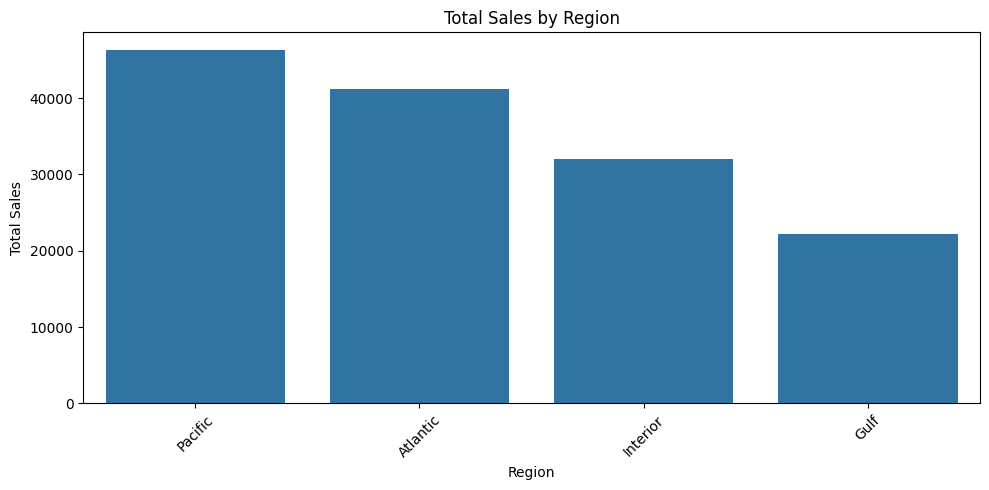

In [17]:

# Step 7.3: Sales by region

plt.figure(figsize=(10, 5))

sns.barplot(
    data=region_summary,
    x="Region",
    y="Sales"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [18]:

# Step 8.1: Product sales and profit analysis

product_summary = (
    eda_df.groupby(
        ["Product ID", "Product Name", "Division"],
        dropna=False
    )
    .agg(
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum"),
        Orders=("Order ID", "nunique")
    )
    .reset_index()
    .sort_values("Sales", ascending=False)
)

product_summary["Profit_Margin_Percent"] = (
    product_summary["Gross_Profit"]
    / product_summary["Sales"].replace(0, np.nan)
    * 100
)

print("Top 10 products by sales:")
display(product_summary.head(10).round(2))


Top 10 products by sales:


,Product ID,Product Name,Division,Sales,Gross_Profit,Units,Orders,Profit_Margin_Percent
4,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Chocolate,28485.00,18610.20,7596,1677,65.33
3,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Chocolate,27874.80,19357.50,7743,1704,69.44
1,CHO-MIL-31000,Wonka Bar - Milk Chocolate,Chocolate,26867.75,17443.37,8267,1768,64.92
0,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Chocolate,24890.40,16593.60,6914,1527,66.67
2,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Chocolate,23574.95,16819.95,6755,1529,71.35
8,OTH-LIC-15000,Lickable Wallpaper,Other,7860.00,3930.00,393,92,50.00
7,OTH-KAZ-38000,Kazookles,Other,1205.75,92.75,371,94,7.69
6,OTH-GUM-21000,Wonka Gum,Other,597.50,310.70,478,118,52.00
9,SUG-EVE-47000,Everlasting Gobstopper,Sugar,130.00,104.00,13,3,80.00
5,OTH-FIZ-56000,Fizzy Lifting Drinks,Sugar,78.75,47.25,21,6,60.00


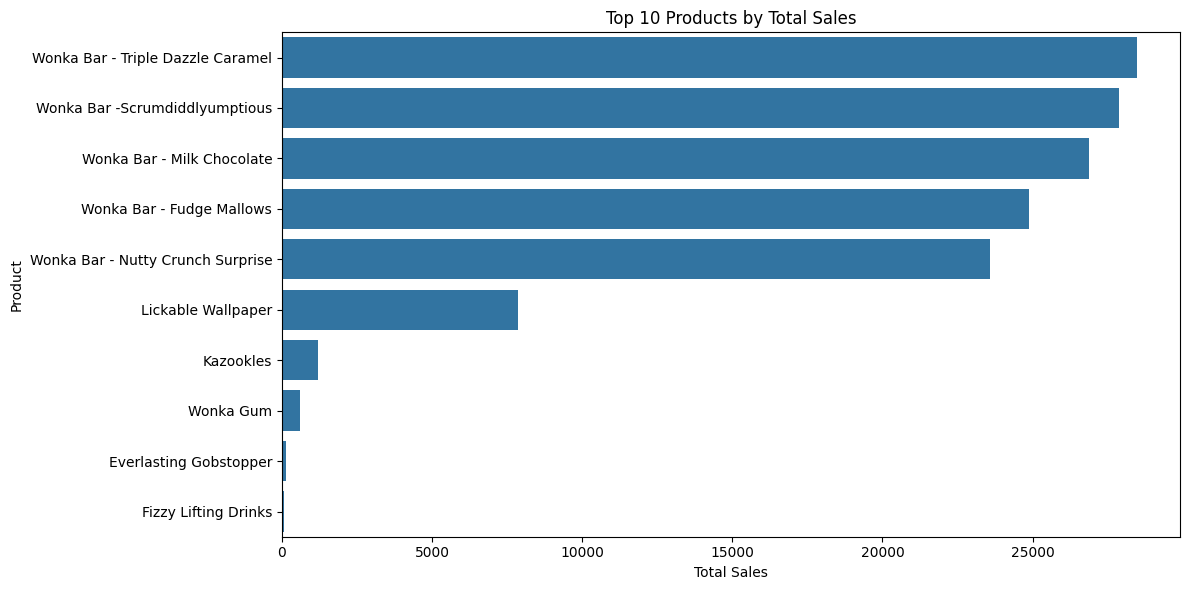

In [19]:

# Step 8.2: Top 10 products by sales

top10_products = product_summary.head(10).copy()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top10_products,
    x="Sales",
    y="Product Name"
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [20]:

# Step 9.1: Division-level sales and profit analysis

division_summary = (
    eda_df.groupby("Division", dropna=False)
    .agg(
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum"),
        Orders=("Order ID", "nunique"),
        Products=("Product ID", "nunique")
    )
    .reset_index()
    .sort_values("Sales", ascending=False)
)

division_summary["Profit_Margin_Percent"] = (
    division_summary["Gross_Profit"]
    / division_summary["Sales"].replace(0, np.nan)
    * 100
)

display(division_summary.round(2))


,Division,Sales,Gross_Profit,Units,Orders,Products,Profit_Margin_Percent
0,Chocolate,131692.90,88824.62,37275,8205,5,67.45
1,Other,9663.25,4333.45,1242,304,3,44.84
2,Sugar,427.48,284.73,137,40,7,66.61


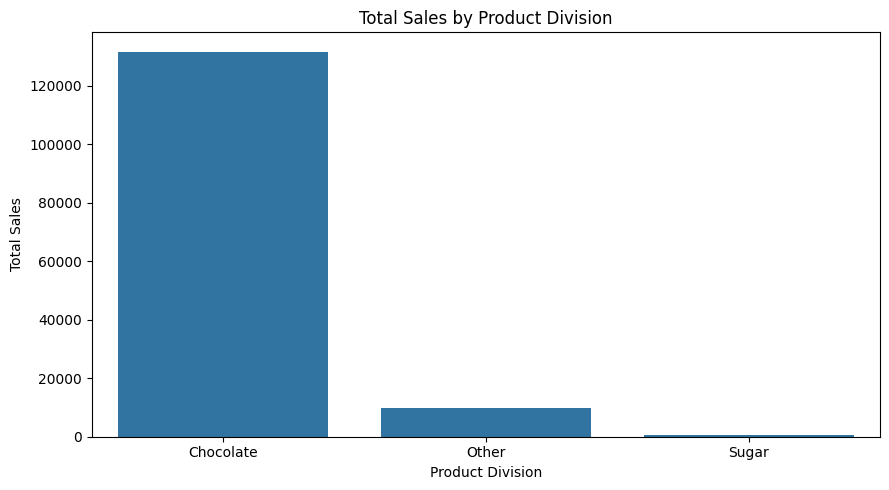

In [21]:

# Step 9.2: Sales by division

plt.figure(figsize=(9, 5))

sns.barplot(
    data=division_summary,
    x="Division",
    y="Sales"
)

plt.title("Total Sales by Product Division")
plt.xlabel("Product Division")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


In [22]:

# Step 9.3: Check product-to-factory mapping

factory_mapping = pd.DataFrame([
    ["Chocolate", "Wonka Bar - Nutty Crunch Surprise", "Lot's O' Nuts"],
    ["Chocolate", "Wonka Bar - Fudge Mallows", "Lot's O' Nuts"],
    ["Chocolate", "Wonka Bar -Scrumdiddlyumptious", "Lot's O' Nuts"],
    ["Chocolate", "Wonka Bar - Milk Chocolate", "Wicked Choccy's"],
    ["Chocolate", "Wonka Bar - Triple Dazzle Caramel", "Wicked Choccy's"],
    ["Sugar", "Laffy Taffy", "Sugar Shack"],
    ["Sugar", "SweeTARTS", "Sugar Shack"],
    ["Sugar", "Nerds", "Sugar Shack"],
    ["Sugar", "Fun Dip", "Sugar Shack"],
    ["Other", "Fizzy Lifting Drinks", "Sugar Shack"],
    ["Sugar", "Everlasting Gobstopper", "Secret Factory"],
    ["Sugar", "Hair Toffee", "The Other Factory"],
    ["Other", "Lickable Wallpaper", "Secret Factory"],
    ["Other", "Wonka Gum", "Secret Factory"],
    ["Other", "Kazookles", "The Other Factory"]
], columns=["Division", "Product Name", "Current Factory"])

print("Products in factory mapping:", len(factory_mapping))
print("\nFactory assignments:")
display(factory_mapping)


Products in factory mapping: 15

Factory assignments:


,Division,Product Name,Current Factory
0,Chocolate,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts
1,Chocolate,Wonka Bar - Fudge Mallows,Lot's O' Nuts
2,Chocolate,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts
3,Chocolate,Wonka Bar - Milk Chocolate,Wicked Choccy's
4,Chocolate,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's
5,Sugar,Laffy Taffy,Sugar Shack
6,Sugar,SweeTARTS,Sugar Shack
7,Sugar,Nerds,Sugar Shack
8,Sugar,Fun Dip,Sugar Shack
9,Other,Fizzy Lifting Drinks,Sugar Shack


In [23]:

# Step 10.1: Standardize product names for matching

def normalize_product_name(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.casefold()
    )

eda_df["Product Key"] = normalize_product_name(
    eda_df["Product Name"]
)

factory_mapping["Product Key"] = normalize_product_name(
    factory_mapping["Product Name"]
)

# Match product mapping against the dataset
dataset_products = (
    eda_df[["Product Key", "Product Name", "Division"]]
    .drop_duplicates()
)

mapping_check = factory_mapping.merge(
    dataset_products,
    on="Product Key",
    how="left",
    suffixes=("_Mapping", "_Dataset"),
    indicator=True
)

print("Factory mapping records:", len(factory_mapping))
print("Matched products:",
      (mapping_check["_merge"] == "both").sum())
print("Unmatched mappings:",
      (mapping_check["_merge"] == "left_only").sum())

print("\nMapping validation:")
display(
    mapping_check[
        ["Product Name_Mapping", "Division_Mapping",
         "Current Factory", "Product Name_Dataset",
         "Division_Dataset", "_merge"]
    ]
)


Factory mapping records: 15
Matched products: 15
Unmatched mappings: 0

Mapping validation:


,Product Name_Mapping,Division_Mapping,Current Factory,Product Name_Dataset,Division_Dataset,_merge
0,Wonka Bar - Nutty Crunch Surprise,Chocolate,Lot's O' Nuts,Wonka Bar - Nutty Crunch Surprise,Chocolate,both
1,Wonka Bar - Fudge Mallows,Chocolate,Lot's O' Nuts,Wonka Bar - Fudge Mallows,Chocolate,both
2,Wonka Bar -Scrumdiddlyumptious,Chocolate,Lot's O' Nuts,Wonka Bar -Scrumdiddlyumptious,Chocolate,both
3,Wonka Bar - Milk Chocolate,Chocolate,Wicked Choccy's,Wonka Bar - Milk Chocolate,Chocolate,both
4,Wonka Bar - Triple Dazzle Caramel,Chocolate,Wicked Choccy's,Wonka Bar - Triple Dazzle Caramel,Chocolate,both
5,Laffy Taffy,Sugar,Sugar Shack,Laffy Taffy,Sugar,both
6,SweeTARTS,Sugar,Sugar Shack,SweeTARTS,Sugar,both
7,Nerds,Sugar,Sugar Shack,Nerds,Sugar,both
8,Fun Dip,Sugar,Sugar Shack,Fun Dip,Sugar,both
9,Fizzy Lifting Drinks,Other,Sugar Shack,Fizzy Lifting Drinks,Sugar,both


In [24]:

# Find distinct dataset products not included in the mapping

mapped_keys = set(factory_mapping["Product Key"].dropna())

unmapped_products = (
    dataset_products[
        ~dataset_products["Product Key"].isin(mapped_keys)
    ]
    .sort_values(["Division", "Product Name"])
)

print("Distinct products in dataset:", len(dataset_products))
print("Products without a factory mapping:",
      len(unmapped_products))

display(unmapped_products)


Distinct products in dataset: 15
Products without a factory mapping: 0


,Product Key,Product Name,Division


In [25]:

# Step 11.1: Attach current factory assignments

factory_lookup = factory_mapping[
    ["Product Key", "Current Factory"]
].drop_duplicates()

factory_df = eda_df.merge(
    factory_lookup,
    on="Product Key",
    how="left",
    validate="many_to_one"
)

print("Original dataset rows:", len(eda_df))
print("Factory dataset rows:", len(factory_df))
print("Rows without factory:",
      factory_df["Current Factory"].isna().sum())

print("\nRecords by factory:")
display(
    factory_df["Current Factory"]
    .value_counts(dropna=False)
    .rename_axis("Factory")
    .to_frame("Record Count")
)


Original dataset rows: 10194
Factory dataset rows: 10194
Rows without factory: 0

Records by factory:


,Record Count
Factory,
Lot's O' Nuts,5692
Wicked Choccy's,4152
Secret Factory,217
The Other Factory,100
Sugar Shack,33


In [26]:

# Step 11.2: Factory-level performance summary

factory_summary = (
    factory_df.groupby("Current Factory", dropna=False)
    .agg(
        Records=("Order ID", "size"),
        Unique_Orders=("Order ID", "nunique"),
        Products=("Product ID", "nunique"),
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum")
    )
    .reset_index()
    .sort_values("Sales", ascending=False)
)

factory_summary["Profit_Margin_Percent"] = (
    factory_summary["Gross_Profit"]
    / factory_summary["Sales"].replace(0, np.nan)
    * 100
)

display(factory_summary.round(2))


,Current Factory,Records,Unique_Orders,Products,Sales,Gross_Profit,Units,Profit_Margin_Percent
0,Lot's O' Nuts,5692,4760,3,76340.15,52771.05,21412,69.13
4,Wicked Choccy's,4152,3445,2,55352.75,36053.57,15863,65.13
1,Secret Factory,217,213,3,8587.50,4344.70,884,50.59
3,The Other Factory,100,98,2,1282.25,152.25,388,11.87
2,Sugar Shack,33,33,5,220.98,121.23,107,54.86


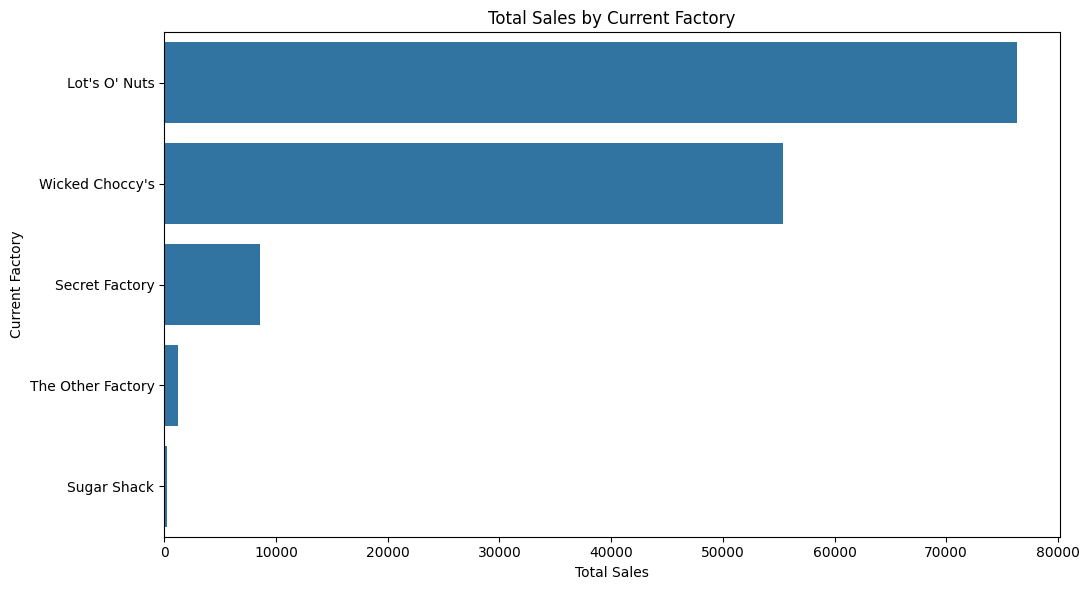

In [27]:

# Step 11.3: Sales comparison across factories

plt.figure(figsize=(11, 6))

sns.barplot(
    data=factory_summary,
    x="Sales",
    y="Current Factory"
)

plt.title("Total Sales by Current Factory")
plt.xlabel("Total Sales")
plt.ylabel("Current Factory")
plt.tight_layout()
plt.show()


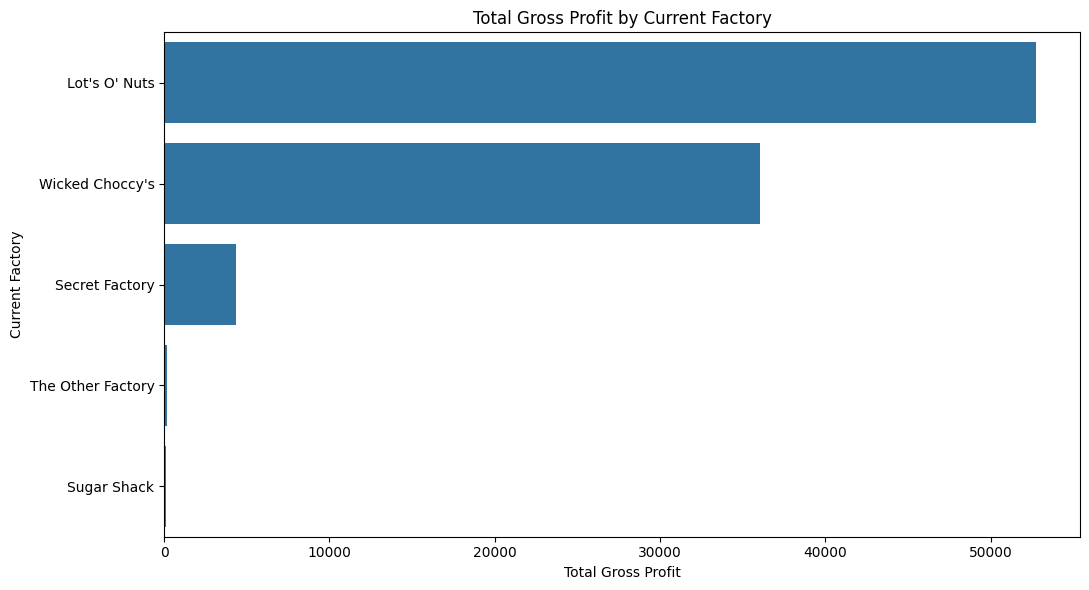

In [28]:

# Step 11.4: Gross profit comparison across factories

plt.figure(figsize=(11, 6))

sns.barplot(
    data=factory_summary,
    x="Gross_Profit",
    y="Current Factory"
)

plt.title("Total Gross Profit by Current Factory")
plt.xlabel("Total Gross Profit")
plt.ylabel("Current Factory")
plt.tight_layout()
plt.show()


In [29]:

# Step 12.1: Product performance within each factory

factory_product_summary = (
    factory_df.groupby(
        ["Current Factory", "Product Name", "Division"],
        dropna=False
    )
    .agg(
        Records=("Order ID", "size"),
        Orders=("Order ID", "nunique"),
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Cost=("Cost", "sum"),
        Units=("Units", "sum")
    )
    .reset_index()
)

factory_product_summary["Profit_Margin_Percent"] = (
    factory_product_summary["Gross_Profit"]
    / factory_product_summary["Sales"].replace(0, np.nan)
    * 100
)

factory_product_summary = factory_product_summary.sort_values(
    "Sales", ascending=False
)

display(factory_product_summary.round(2))


,Current Factory,Product Name,Division,Records,Orders,Sales,Gross_Profit,Cost,Units,Profit_Margin_Percent
14,Wicked Choccy's,Wonka Bar - Triple Dazzle Caramel,Chocolate,2015,1677,28485.00,18610.20,9874.80,7596,65.33
2,Lot's O' Nuts,Wonka Bar -Scrumdiddlyumptious,Chocolate,2064,1704,27874.80,19357.50,8517.30,7743,69.44
13,Wicked Choccy's,Wonka Bar - Milk Chocolate,Chocolate,2137,1768,26867.75,17443.37,9424.38,8267,64.92
0,Lot's O' Nuts,Wonka Bar - Fudge Mallows,Chocolate,1818,1527,24890.40,16593.60,8296.80,6914,66.67
1,Lot's O' Nuts,Wonka Bar - Nutty Crunch Surprise,Chocolate,1810,1529,23574.95,16819.95,6755.00,6755,71.35
4,Secret Factory,Lickable Wallpaper,Other,94,92,7860.00,3930.00,3930.00,393,50.00
12,The Other Factory,Kazookles,Other,96,94,1205.75,92.75,1113.00,371,7.69
5,Secret Factory,Wonka Gum,Other,120,118,597.50,310.70,286.80,478,52.00
3,Secret Factory,Everlasting Gobstopper,Sugar,3,3,130.00,104.00,26.00,13,80.00
6,Sugar Shack,Fizzy Lifting Drinks,Sugar,6,6,78.75,47.25,31.50,21,60.00


In [30]:

# Step 12.2: Flag products with low or negative profit margins

factory_product_summary["Margin_Flag"] = np.select(
    [
        factory_product_summary["Profit_Margin_Percent"] < 0,
        factory_product_summary["Profit_Margin_Percent"] < 15,
        factory_product_summary["Profit_Margin_Percent"] < 30
    ],
    [
        "Negative margin",
        "Below 15%",
        "15% to below 30%"
    ],
    default="30% or above"
)

display(
    factory_product_summary[
        [
            "Current Factory", "Product Name",
            "Sales", "Gross_Profit",
            "Cost", "Units",
            "Profit_Margin_Percent", "Margin_Flag"
        ]
    ].sort_values("Profit_Margin_Percent").round(2)
)


,Current Factory,Product Name,Sales,Gross_Profit,Cost,Units,Profit_Margin_Percent,Margin_Flag
12,The Other Factory,Kazookles,1205.75,92.75,1113.00,371,7.69,Below 15%
7,Sugar Shack,Fun Dip,12.00,4.80,7.20,8,40.00,30% or above
10,Sugar Shack,SweeTARTS,61.50,28.70,32.80,41,46.67,30% or above
9,Sugar Shack,Nerds,15.00,7.00,8.00,10,46.67,30% or above
4,Secret Factory,Lickable Wallpaper,7860.00,3930.00,3930.00,393,50.00,30% or above
5,Secret Factory,Wonka Gum,597.50,310.70,286.80,478,52.00,30% or above
6,Sugar Shack,Fizzy Lifting Drinks,78.75,47.25,31.50,21,60.00,30% or above
8,Sugar Shack,Laffy Taffy,53.73,33.48,20.25,27,62.31,30% or above
13,Wicked Choccy's,Wonka Bar - Milk Chocolate,26867.75,17443.37,9424.38,8267,64.92,30% or above
14,Wicked Choccy's,Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,9874.80,7596,65.33,30% or above


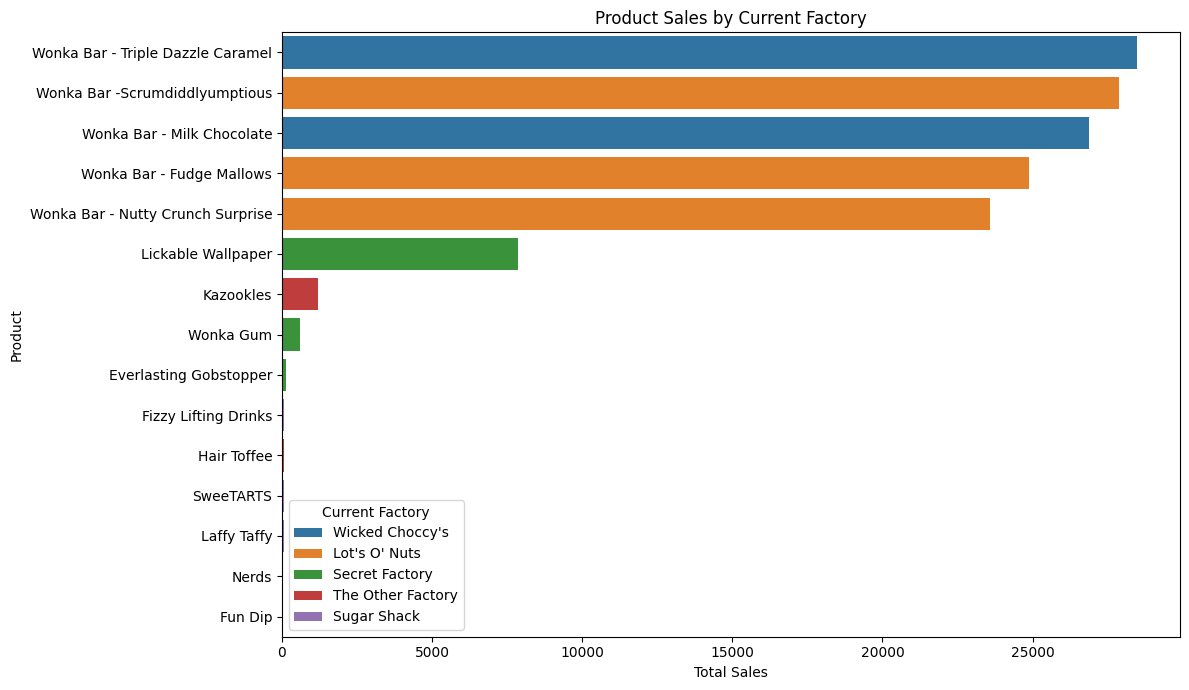

In [31]:

# Step 12.3: Product-level sales chart

plt.figure(figsize=(12, 7))

sns.barplot(
    data=factory_product_summary,
    x="Sales",
    y="Product Name",
    hue="Current Factory"
)

plt.title("Product Sales by Current Factory")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [32]:

# Step 13.1: Create the factory coordinates table

factory_locations = pd.DataFrame([
    ["Lot's O' Nuts", 32.881893, -111.768036],
    ["Wicked Choccy's", 32.076176, -81.088371],
    ["Sugar Shack", 48.119140, -96.181150],
    ["Secret Factory", 41.446333, -90.565487],
    ["The Other Factory", 35.117500, -89.971107]
], columns=["Current Factory", "Latitude", "Longitude"])

print("Factory locations:")
display(factory_locations)


Factory locations:


,Current Factory,Latitude,Longitude
0,Lot's O' Nuts,32.881893,-111.768036
1,Wicked Choccy's,32.076176,-81.088371
2,Sugar Shack,48.119140,-96.181150
3,Secret Factory,41.446333,-90.565487
4,The Other Factory,35.117500,-89.971107


In [33]:

# Step 13.2: Validate factory names

mapped_factories = set(factory_mapping["Current Factory"].unique())
coordinate_factories = set(factory_locations["Current Factory"].unique())

print("Factories in product mapping:", len(mapped_factories))
print("Factories with coordinates:", len(coordinate_factories))

print("\nFactories missing coordinates:")
print(sorted(mapped_factories - coordinate_factories))

print("\nUnused coordinate entries:")
print(sorted(coordinate_factories - mapped_factories))


Factories in product mapping: 5
Factories with coordinates: 5

Factories missing coordinates:
[]

Unused coordinate entries:
[]


In [34]:

# Step 13.3: Combine factory metrics with coordinates

factory_geo_summary = factory_summary.merge(
    factory_locations,
    on="Current Factory",
    how="left",
    validate="one_to_one"
)

display(factory_geo_summary.round(3))

print(
    "\nFactories without coordinates:",
    factory_geo_summary["Latitude"].isna().sum()
)


,Current Factory,Records,Unique_Orders,Products,Sales,Gross_Profit,Units,Profit_Margin_Percent,Latitude,Longitude
0,Lot's O' Nuts,5692,4760,3,76340.15,52771.05,21412,69.126,32.882,-111.768
1,Wicked Choccy's,4152,3445,2,55352.75,36053.57,15863,65.134,32.076,-81.088
2,Secret Factory,217,213,3,8587.50,4344.70,884,50.593,41.446,-90.565
3,The Other Factory,100,98,2,1282.25,152.25,388,11.874,35.118,-89.971
4,Sugar Shack,33,33,5,220.98,121.23,107,54.860,48.119,-96.181



Factories without coordinates: 0


In [35]:

# Step 14.1: Calculate straight-line distances between factories

from math import radians, sin, cos, asin, sqrt

def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius_km = 6371.0

    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2) ** 2
        + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    )

    return 2 * earth_radius_km * asin(sqrt(a))

factories = factory_locations["Current Factory"].tolist()

distance_matrix = pd.DataFrame(
    index=factories,
    columns=factories,
    dtype=float
)

for _, f1 in factory_locations.iterrows():
    for _, f2 in factory_locations.iterrows():
        distance_matrix.loc[
            f1["Current Factory"], f2["Current Factory"]
        ] = haversine_km(
            f1["Latitude"], f1["Longitude"],
            f2["Latitude"], f2["Longitude"]
        )

print("Factory-to-factory distance matrix (km):")
display(distance_matrix.round(1))


Factory-to-factory distance matrix (km):


,Lot's O' Nuts,Wicked Choccy's,Sugar Shack,Secret Factory,The Other Factory
Lot's O' Nuts,0.0,2869.1,2137.8,2098.6,2020.6
Wicked Choccy's,2869.1,0.0,2189.2,1339.2,889.1
Sugar Shack,2137.8,2189.2,0.0,863.7,1533.8
Secret Factory,2098.6,1339.2,863.7,0.0,705.6
The Other Factory,2020.6,889.1,1533.8,705.6,0.0


In [36]:

# Step 14.2: Find the nearest alternative for each factory

nearest_alternatives = []

for factory in factories:
    alternatives = distance_matrix.loc[factory].drop(factory)
    nearest_factory = alternatives.idxmin()

    nearest_alternatives.append({
        "Current Factory": factory,
        "Nearest Alternative": nearest_factory,
        "Straight_Line_Distance_km": alternatives.min()
    })

nearest_df = pd.DataFrame(nearest_alternatives)

display(
    nearest_df.sort_values("Straight_Line_Distance_km")
    .round(1)
)


,Current Factory,Nearest Alternative,Straight_Line_Distance_km
3,Secret Factory,The Other Factory,705.6
4,The Other Factory,Secret Factory,705.6
2,Sugar Shack,Secret Factory,863.7
1,Wicked Choccy's,The Other Factory,889.1
0,Lot's O' Nuts,The Other Factory,2020.6


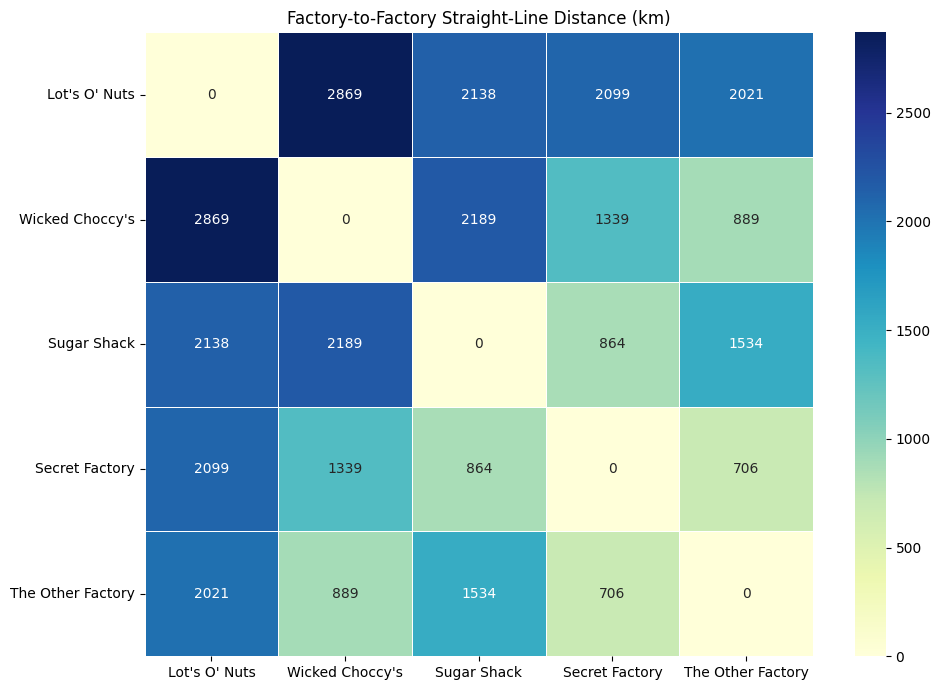

In [37]:

# Step 14.3: Visualize straight-line factory distances

plt.figure(figsize=(10, 7))

sns.heatmap(
    distance_matrix,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Factory-to-Factory Straight-Line Distance (km)")
plt.tight_layout()
plt.show()


In [38]:

# Step 15.1: Analyze destination regions

destination_summary = (
    factory_df.groupby(
        ["Country/Region", "Region", "State/Province"],
        dropna=False
    )
    .agg(
        Records=("Order ID", "size"),
        Unique_Orders=("Order ID", "nunique"),
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(destination_summary.head(20).round(2))


,Country/Region,Region,State/Province,Records,Unique_Orders,Sales,Gross_Profit,Units
49,United States,Pacific,California,2001,1686,27917.40,18479.42,7667
18,United States,Atlantic,New York,1128,942,15541.03,10222.44,4224
46,United States,Interior,Texas,985,833,13416.09,8909.53,3724
20,United States,Atlantic,Pennsylvania,587,487,8027.03,5225.47,2153
57,United States,Pacific,Washington,506,432,6921.15,4566.64,1883
35,United States,Interior,Illinois,492,433,6898.96,4557.68,1845
19,United States,Atlantic,Ohio,469,392,6768.95,4413.03,1759
26,United States,Gulf,Florida,383,319,4804.02,3207.11,1379
39,United States,Interior,Michigan,255,209,3331.00,2236.21,946
31,United States,Gulf,North Carolina,249,216,3450.86,2331.16,983


In [39]:

# Step 15.2: Summarize customer cities

city_summary = (
    factory_df.groupby(
        ["Country/Region", "State/Province", "City"],
        dropna=False
    )
    .agg(
        Records=("Order ID", "size"),
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(city_summary.head(20).round(2))


,Country/Region,State/Province,City,Records,Sales,Gross_Profit
401,United States,New York,New York City,915,12514.90,8240.51
75,United States,California,Los Angeles,747,10408.75,6898.61
475,United States,Pennsylvania,Philadelphia,537,7415.52,4813.82
102,United States,California,San Francisco,510,7018.61,4650.77
598,United States,Washington,Seattle,428,5893.39,3880.68
533,United States,Texas,Houston,377,5429.41,3547.43
213,United States,Illinois,Chicago,314,4263.92,2800.58
101,United States,California,San Diego,170,2348.88,1567.52
522,United States,Texas,Dallas,157,1947.51,1299.77
434,United States,Ohio,Columbus,120,1845.30,1203.86


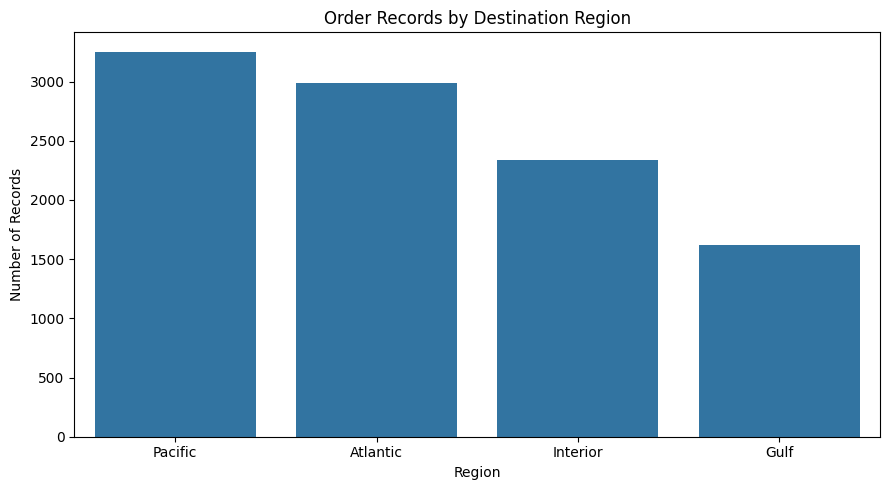

In [40]:

# Step 15.3: Order records by region

region_records = (
    factory_df.groupby("Region", dropna=False)
    .size()
    .reset_index(name="Records")
    .sort_values("Records", ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_records,
    x="Region",
    y="Records"
)

plt.title("Order Records by Destination Region")
plt.xlabel("Region")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


In [41]:

# Step 16.1: Approximate coordinates for common destination cities

city_coordinates = pd.DataFrame([
    ["United States", "New York", "New York City", 40.7128, -74.0060],
    ["United States", "California", "Los Angeles", 34.0522, -118.2437],
    ["United States", "Pennsylvania", "Philadelphia", 39.9526, -75.1652],
    ["United States", "California", "San Francisco", 37.7749, -122.4194],
    ["United States", "Washington", "Seattle", 47.6062, -122.3321],
    ["United States", "Texas", "Houston", 29.7604, -95.3698],
    ["United States", "Illinois", "Chicago", 41.8781, -87.6298],
    ["United States", "California", "San Diego", 32.7157, -117.1611],
    ["United States", "Texas", "Dallas", 32.7767, -96.7970],
    ["United States", "Ohio", "Columbus", 39.9612, -82.9988],
    ["United States", "Michigan", "Detroit", 42.3314, -83.0458],
    ["United States", "Florida", "Jacksonville", 30.3322, -81.6557],
    ["United States", "Arizona", "Phoenix", 33.4484, -112.0740],
    ["Canada", "Ontario", "Toronto", 43.6532, -79.3832],
    ["United States", "Florida", "Miami", 25.7617, -80.1918],
    ["United States", "North Carolina", "Charlotte", 35.2271, -80.8431],
], columns=[
    "Country/Region", "State/Province", "City",
    "City Latitude", "City Longitude"
])

print("Mapped destination cities:", len(city_coordinates))
display(city_coordinates)


Mapped destination cities: 16


,Country/Region,State/Province,City,City Latitude,City Longitude
0,United States,New York,New York City,40.7128,-74.0060
1,United States,California,Los Angeles,34.0522,-118.2437
2,United States,Pennsylvania,Philadelphia,39.9526,-75.1652
3,United States,California,San Francisco,37.7749,-122.4194
4,United States,Washington,Seattle,47.6062,-122.3321
5,United States,Texas,Houston,29.7604,-95.3698
6,United States,Illinois,Chicago,41.8781,-87.6298
7,United States,California,San Diego,32.7157,-117.1611
8,United States,Texas,Dallas,32.7767,-96.7970
9,United States,Ohio,Columbus,39.9612,-82.9988


In [42]:

# Step 16.2: Validate destination coordinate coverage

destination_keys = [
    "Country/Region", "State/Province", "City"
]

city_check = city_summary.merge(
    city_coordinates,
    on=destination_keys,
    how="left",
    indicator=True
)

print("Cities with coordinates:",
      (city_check["_merge"] == "both").sum())

print("Cities without coordinates:",
      (city_check["_merge"] == "left_only").sum())

print("\nTop 20 city coverage:")
display(
    city_check[
        destination_keys + ["Records", "_merge"]
    ].head(20)
)


Cities with coordinates: 16
Cities without coordinates: 600

Top 20 city coverage:


,Country/Region,State/Province,City,Records,_merge
0,United States,New York,New York City,915,both
1,United States,California,Los Angeles,747,both
2,United States,Pennsylvania,Philadelphia,537,both
3,United States,California,San Francisco,510,both
4,United States,Washington,Seattle,428,both
5,United States,Texas,Houston,377,both
6,United States,Illinois,Chicago,314,both
7,United States,California,San Diego,170,both
8,United States,Texas,Dallas,157,both
9,United States,Ohio,Columbus,120,both


In [43]:

# Step 17.1: Match mapped cities and calculate factory distances

mapped_destinations = city_check.loc[
    city_check["_merge"] == "both"
].copy()

distance_results = []

for _, city in mapped_destinations.iterrows():
    for _, factory in factory_locations.iterrows():
        distance_km = haversine_km(
            factory["Latitude"],
            factory["Longitude"],
            city["City Latitude"],
            city["City Longitude"]
        )

        distance_results.append({
            "Country/Region": city["Country/Region"],
            "State/Province": city["State/Province"],
            "City": city["City"],
            "Records": city["Records"],
            "Factory": factory["Current Factory"],
            "Distance_km": distance_km
        })

factory_city_distances = pd.DataFrame(distance_results)

print("Factory-city distance combinations:",
      len(factory_city_distances))

display(factory_city_distances.head(20).round(1))


Factory-city distance combinations: 80


,Country/Region,State/Province,City,Records,Factory,Distance_km
0,United States,New York,New York City,915,Lot's O' Nuts,3444.7
1,United States,New York,New York City,915,Wicked Choccy's,1149.8
2,United States,New York,New York City,915,Sugar Shack,1935.0
3,United States,New York,New York City,915,Secret Factory,1388.3
4,United States,New York,New York City,915,The Other Factory,1529.5
5,United States,California,Los Angeles,747,Lot's O' Nuts,614.5
6,United States,California,Los Angeles,747,Wicked Choccy's,3450.5
7,United States,California,Los Angeles,747,Sugar Shack,2406.4
8,United States,California,Los Angeles,747,Secret Factory,2555.6
9,United States,California,Los Angeles,747,The Other Factory,2582.3


In [44]:

# Step 17.2: Rank factories by distance for each destination

nearest_factory_by_city = (
    factory_city_distances.sort_values("Distance_km")
    .groupby(
        ["Country/Region", "State/Province", "City"],
        as_index=False
    )
    .first()
)

print("Nearest factory for each mapped city:")
display(
    nearest_factory_by_city[
        ["Country/Region", "State/Province", "City",
         "Records", "Factory", "Distance_km"]
    ].round(1)
)


Nearest factory for each mapped city:


,Country/Region,State/Province,City,Records,Factory,Distance_km
0,Canada,Ontario,Toronto,58,Secret Factory,947.5
1,United States,Arizona,Phoenix,63,Lot's O' Nuts,69.1
2,United States,California,Los Angeles,747,Lot's O' Nuts,614.5
3,United States,California,San Diego,170,Lot's O' Nuts,504.4
4,United States,California,San Francisco,510,Lot's O' Nuts,1107.9
5,United States,Florida,Jacksonville,75,Wicked Choccy's,201.3
6,United States,Florida,Miami,57,Wicked Choccy's,707.5
7,United States,Illinois,Chicago,314,Secret Factory,248.5
8,United States,Michigan,Detroit,115,Secret Factory,630.0
9,United States,New York,New York City,915,Wicked Choccy's,1149.8


In [45]:

# Step 17.3: Weighted distance summary for mapped destinations

distance_summary = (
    factory_city_distances.groupby("Factory")
    .apply(
        lambda group: pd.Series({
            "Mapped_City_Records": group["Records"].sum(),
            "Weighted_Average_Distance_km": (
                (group["Distance_km"] * group["Records"]).sum()
                / group["Records"].sum()
            )
        }),
        include_groups=False
    )
    .reset_index()
    .sort_values("Weighted_Average_Distance_km")
)

display(distance_summary.round(1))


,Factory,Mapped_City_Records,Weighted_Average_Distance_km
1,Secret Factory,4695.0,1748.1
3,The Other Factory,4695.0,1818.4
2,Sugar Shack,4695.0,1994.0
0,Lot's O' Nuts,4695.0,2080.6
4,Wicked Choccy's,4695.0,2140.8


In [46]:

# Step 18.1: Attach current factory to each mapped destination record

mapped_orders = factory_df.merge(
    city_coordinates,
    on=["Country/Region", "State/Province", "City"],
    how="inner",
    validate="many_to_one"
)

print("Orders with mapped city coordinates:", len(mapped_orders))
print("Coverage (%):", round(
    len(mapped_orders) / len(factory_df) * 100, 2
))

display(
    mapped_orders[
        ["Order ID", "Product Name", "Current Factory",
         "City", "City Latitude", "City Longitude"]
    ].head(10)
)


Orders with mapped city coordinates: 4695
Coverage (%): 46.06


,Order ID,Product Name,Current Factory,City,City Latitude,City Longitude
0,US-2021-103800-CHO-MIL-31000,Wonka Bar - Milk Chocolate,Wicked Choccy's,Houston,29.7604,-95.3698
1,US-2021-141817-CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Philadelphia,39.9526,-75.1652
2,US-2021-130813-CHO-MIL-31000,Wonka Bar - Milk Chocolate,Wicked Choccy's,Los Angeles,34.0522,-118.2437
3,US-2021-157147-CHO-MIL-31000,Wonka Bar - Milk Chocolate,Wicked Choccy's,San Francisco,37.7749,-122.4194
4,US-2021-157147-CHO-MIL-31000,Wonka Bar - Milk Chocolate,Wicked Choccy's,San Francisco,37.7749,-122.4194
5,US-2021-157147-CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,San Francisco,37.7749,-122.4194
6,US-2021-149524-OTH-GUM-21000,Wonka Gum,Secret Factory,Philadelphia,39.9526,-75.1652
7,US-2021-115791-CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Philadelphia,39.9526,-75.1652
8,US-2021-115791-CHO-FUD-51000,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Philadelphia,39.9526,-75.1652
9,US-2021-115791-CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Philadelphia,39.9526,-75.1652


In [47]:

# Step 18.2: Compare current factory with nearest factory

def distance_to_factory(row, factory_name):
    factory = factory_locations.loc[
        factory_locations["Current Factory"] == factory_name
    ].iloc[0]

    return haversine_km(
        factory["Latitude"],
        factory["Longitude"],
        row["City Latitude"],
        row["City Longitude"]
    )

mapped_orders["Current_Distance_km"] = mapped_orders.apply(
    lambda row: distance_to_factory(
        row, row["Current Factory"]
    ),
    axis=1
)

nearest_lookup = nearest_factory_by_city[
    ["Country/Region", "State/Province", "City",
     "Factory", "Distance_km"]
].rename(columns={
    "Factory": "Nearest_Factory",
    "Distance_km": "Nearest_Distance_km"
})

mapped_orders = mapped_orders.merge(
    nearest_lookup,
    on=["Country/Region", "State/Province", "City"],
    how="left",
    validate="many_to_one"
)

mapped_orders["Distance_Difference_km"] = (
    mapped_orders["Current_Distance_km"]
    - mapped_orders["Nearest_Distance_km"]
)

print("Current versus nearest factory distance:")
display(
    mapped_orders[
        ["Product Name", "Current Factory", "City",
         "Current_Distance_km", "Nearest_Factory",
         "Nearest_Distance_km", "Distance_Difference_km"]
    ].head(20).round(1)
)


Current versus nearest factory distance:


,Product Name,Current Factory,City,Current_Distance_km,Nearest_Factory,Nearest_Distance_km,Distance_Difference_km
0,Wonka Bar - Milk Chocolate,Wicked Choccy's,Houston,1385.4,The Other Factory,781.7,603.7
1,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Philadelphia,1024.5,Wicked Choccy's,1024.5,0.0
2,Wonka Bar - Milk Chocolate,Wicked Choccy's,Los Angeles,3450.5,Lot's O' Nuts,614.5,2836.0
3,Wonka Bar - Milk Chocolate,Wicked Choccy's,San Francisco,3789.9,Lot's O' Nuts,1107.9,2682.0
4,Wonka Bar - Milk Chocolate,Wicked Choccy's,San Francisco,3789.9,Lot's O' Nuts,1107.9,2682.0
5,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,San Francisco,1107.9,Lot's O' Nuts,1107.9,0.0
6,Wonka Gum,Secret Factory,Philadelphia,1307.1,Wicked Choccy's,1024.5,282.6
7,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Philadelphia,1024.5,Wicked Choccy's,1024.5,0.0
8,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Philadelphia,3343.3,Wicked Choccy's,1024.5,2318.8
9,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Philadelphia,1024.5,Wicked Choccy's,1024.5,0.0


In [48]:

# Step 18.3: Weighted distance-only comparison

total_records = mapped_orders["Records"].sum() if "Records" in mapped_orders.columns else len(mapped_orders)

current_avg = mapped_orders["Current_Distance_km"].mean()
nearest_avg = mapped_orders["Nearest_Distance_km"].mean()

print("Mapped order records:", len(mapped_orders))
print("Average current-factory distance (km):", round(current_avg, 1))
print("Average nearest-factory distance (km):", round(nearest_avg, 1))
print("Average distance difference (km):",
      round(current_avg - nearest_avg, 1))
print("Distance reduction (%):",
      round(
          (current_avg - nearest_avg) / current_avg * 100, 2
      ) if current_avg else 0)


Mapped order records: 4695
Average current-factory distance (km): 2125.3
Average nearest-factory distance (km): 910.2
Average distance difference (km): 1215.2
Distance reduction (%): 57.17


In [49]:

# Step 19.1: Product-level factory comparison

product_factory_distances = []

for product in mapped_orders["Product Name"].dropna().unique():
    product_orders = mapped_orders[
        mapped_orders["Product Name"] == product
    ]

    current_factories = product_orders["Current Factory"].unique()

    if len(current_factories) != 1:
        print("Review inconsistent assignments:", product)
        continue

    current_factory = current_factories[0]

    current_distances = product_orders.apply(
        lambda row: distance_to_factory(row, current_factory),
        axis=1
    )

    current_avg = current_distances.mean()

    for candidate in factories:
        candidate_distances = product_orders.apply(
            lambda row: distance_to_factory(row, candidate),
            axis=1
        )

        candidate_avg = candidate_distances.mean()

        product_factory_distances.append({
            "Product Name": product,
            "Current Factory": current_factory,
            "Candidate Factory": candidate,
            "Mapped Records": len(product_orders),
            "Current Avg Distance km": current_avg,
            "Candidate Avg Distance km": candidate_avg,
            "Distance Reduction km": current_avg - candidate_avg
        })

product_factory_comparison = pd.DataFrame(
    product_factory_distances
)

display(product_factory_comparison.round(1))


,Product Name,Current Factory,Candidate Factory,Mapped Records,Current Avg Distance km,Candidate Avg Distance km,Distance Reduction km
0,Wonka Bar - Milk Chocolate,Wicked Choccy's,Lot's O' Nuts,989,2146.7,2038.3,108.4
1,Wonka Bar - Milk Chocolate,Wicked Choccy's,Wicked Choccy's,989,2146.7,2146.7,0.0
2,Wonka Bar - Milk Chocolate,Wicked Choccy's,Sugar Shack,989,2146.7,1986.1,160.6
3,Wonka Bar - Milk Chocolate,Wicked Choccy's,Secret Factory,989,2146.7,1738.8,407.9
4,Wonka Bar - Milk Chocolate,Wicked Choccy's,The Other Factory,989,2146.7,1805.8,340.9
...,...,...,...,...,...,...,...
65,SweeTARTS,Sugar Shack,Lot's O' Nuts,3,2128.8,2048.9,79.9
66,SweeTARTS,Sugar Shack,Wicked Choccy's,3,2128.8,2108.3,20.4
67,SweeTARTS,Sugar Shack,Sugar Shack,3,2128.8,2128.8,0.0
68,SweeTARTS,Sugar Shack,Secret Factory,3,2128.8,1833.7,295.1


In [50]:

# Step 19.2: Rank the best alternative by distance

alternatives = product_factory_comparison[
    product_factory_comparison["Candidate Factory"]
    != product_factory_comparison["Current Factory"]
].copy()

best_alternatives = (
    alternatives.sort_values(
        ["Product Name", "Candidate Avg Distance km"]
    )
    .groupby("Product Name", as_index=False)
    .first()
)

best_alternatives["Distance Reduction Percent"] = (
    best_alternatives["Distance Reduction km"]
    / best_alternatives["Current Avg Distance km"].replace(0, np.nan)
    * 100
)

display(
    best_alternatives[
        [
            "Product Name",
            "Current Factory",
            "Candidate Factory",
            "Mapped Records",
            "Current Avg Distance km",
            "Candidate Avg Distance km",
            "Distance Reduction km",
            "Distance Reduction Percent"
        ]
    ].sort_values(
        "Distance Reduction km", ascending=False
    ).round(2)
)


,Product Name,Current Factory,Candidate Factory,Mapped Records,Current Avg Distance km,Candidate Avg Distance km,Distance Reduction km,Distance Reduction Percent
0,Fizzy Lifting Drinks,Sugar Shack,Wicked Choccy's,4,1783.15,902.44,880.71,49.39
6,Nerds,Sugar Shack,Wicked Choccy's,4,1926.50,1118.44,808.06,41.94
1,Fun Dip,Sugar Shack,Secret Factory,2,1450.09,818.40,631.69,43.56
4,Laffy Taffy,Sugar Shack,Wicked Choccy's,5,2008.96,1477.62,531.34,26.45
11,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Secret Factory,949,2211.67,1781.17,430.49,19.46
9,Wonka Bar - Milk Chocolate,Wicked Choccy's,Secret Factory,989,2146.70,1738.82,407.88,19.00
12,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Secret Factory,948,2139.41,1741.25,398.16,18.61
7,SweeTARTS,Sugar Shack,The Other Factory,3,2128.78,1738.01,390.77,18.36
8,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,847,2119.31,1733.42,385.88,18.21
10,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,804,2061.47,1758.36,303.11,14.70


In [51]:

# Step 19.3: Export for review

best_alternatives.to_csv(
    "Nassau_Product_Factory_Distance_Scenarios.csv",
    index=False
)

print("Distance scenario file created.")
files.download(
    "Nassau_Product_Factory_Distance_Scenarios.csv"
)


Distance scenario file created.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:

# Step 20.1: Validate product coverage and candidate quality

mapped_product_counts = (
    mapped_orders.groupby("Product Name")
    .size()
    .rename("Mapped_Order_Records")
)

current_product_profit = (
    factory_product_summary[
        ["Product Name", "Current Factory", "Sales",
         "Gross_Profit", "Profit_Margin_Percent"]
    ]
    .drop_duplicates("Product Name")
)

recommendation_check = best_alternatives.merge(
    current_product_profit,
    on=["Product Name", "Current Factory"],
    how="left",
    validate="one_to_one"
)

recommendation_check = recommendation_check.merge(
    mapped_product_counts,
    on="Product Name",
    how="left"
)

recommendation_check["Mapped_Order_Records"] = (
    recommendation_check["Mapped_Order_Records"].fillna(0).astype(int)
)

recommendation_check["Evidence Level"] = np.select(
    [
        recommendation_check["Mapped_Order_Records"] < 10,
        recommendation_check["Mapped_Order_Records"] < 100
    ],
    [
        "Very limited mapped data",
        "Limited mapped data"
    ],
    default="More mapped data available"
)

recommendation_check["Feasibility Status"] = (
    "Requires factory eligibility and cost validation"
)

display(
    recommendation_check[
        [
            "Product Name",
            "Current Factory",
            "Candidate Factory",
            "Mapped_Order_Records",
            "Distance Reduction km",
            "Distance Reduction Percent",
            "Profit_Margin_Percent",
            "Evidence Level",
            "Feasibility Status"
        ]
    ]
    .sort_values("Distance Reduction km", ascending=False)
    .round(2)
)


,Product Name,Current Factory,Candidate Factory,Mapped_Order_Records,Distance Reduction km,Distance Reduction Percent,Profit_Margin_Percent,Evidence Level,Feasibility Status
0,Fizzy Lifting Drinks,Sugar Shack,Wicked Choccy's,4,880.71,49.39,60.00,Very limited mapped data,Requires factory eligibility and cost validation
6,Nerds,Sugar Shack,Wicked Choccy's,4,808.06,41.94,46.67,Very limited mapped data,Requires factory eligibility and cost validation
1,Fun Dip,Sugar Shack,Secret Factory,2,631.69,43.56,40.00,Very limited mapped data,Requires factory eligibility and cost validation
4,Laffy Taffy,Sugar Shack,Wicked Choccy's,5,531.34,26.45,62.31,Very limited mapped data,Requires factory eligibility and cost validation
11,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Secret Factory,949,430.49,19.46,65.33,More mapped data available,Requires factory eligibility and cost validation
9,Wonka Bar - Milk Chocolate,Wicked Choccy's,Secret Factory,989,407.88,19.00,64.92,More mapped data available,Requires factory eligibility and cost validation
12,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Secret Factory,948,398.16,18.61,69.44,More mapped data available,Requires factory eligibility and cost validation
7,SweeTARTS,Sugar Shack,The Other Factory,3,390.77,18.36,46.67,Very limited mapped data,Requires factory eligibility and cost validation
8,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,847,385.88,18.21,66.67,More mapped data available,Requires factory eligibility and cost validation
10,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,804,303.11,14.70,71.35,More mapped data available,Requires factory eligibility and cost validation


In [53]:

# Step 20.2: Find products missing from the geographic analysis

products_in_mapping = set(factory_mapping["Product Name"])
products_in_distance_analysis = set(
    product_factory_comparison["Product Name"]
)

products_without_mapped_orders = sorted(
    products_in_mapping - products_in_distance_analysis
)

print(
    "Products without mapped-city records:",
    len(products_without_mapped_orders)
)

for product in products_without_mapped_orders:
    print("-", product)


Products without mapped-city records: 1
- Everlasting Gobstopper


In [54]:

# Step 20.3: Save the preliminary recommendation shortlist

recommendation_check.to_csv(
    "Nassau_Preliminary_Factory_Recommendations.csv",
    index=False
)

print("Preliminary shortlist exported.")
files.download(
    "Nassau_Preliminary_Factory_Recommendations.csv"
)


Preliminary shortlist exported.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [55]:

# Step 21.1: Check proposed assignments against the original mapping

current_assignments = (
    factory_mapping[
        ["Product Name", "Current Factory"]
    ]
    .drop_duplicates()
    .rename(columns={
        "Current Factory": "Authorized_Current_Factory"
    })
)

eligibility_check = best_alternatives.merge(
    current_assignments,
    on="Product Name",
    how="left",
    validate="many_to_one"
)

eligibility_check["Assignment_Status"] = np.where(
    eligibility_check["Candidate Factory"]
    == eligibility_check["Authorized_Current_Factory"],
    "Current assignment",
    "Proposed reassignment - approval required"
)

print("Factory assignment validation:")
display(
    eligibility_check[
        [
            "Product Name",
            "Authorized_Current_Factory",
            "Candidate Factory",
            "Distance Reduction km",
            "Assignment_Status"
        ]
    ].round(2)
)


Factory assignment validation:


,Product Name,Authorized_Current_Factory,Candidate Factory,Distance Reduction km,Assignment_Status
0,Fizzy Lifting Drinks,Sugar Shack,Wicked Choccy's,880.71,Proposed reassignment - approval required
1,Fun Dip,Sugar Shack,Secret Factory,631.69,Proposed reassignment - approval required
2,Hair Toffee,The Other Factory,Secret Factory,83.93,Proposed reassignment - approval required
3,Kazookles,The Other Factory,Secret Factory,46.39,Proposed reassignment - approval required
4,Laffy Taffy,Sugar Shack,Wicked Choccy's,531.34,Proposed reassignment - approval required
5,Lickable Wallpaper,Secret Factory,The Other Factory,-153.40,Proposed reassignment - approval required
6,Nerds,Sugar Shack,Wicked Choccy's,808.06,Proposed reassignment - approval required
7,SweeTARTS,Sugar Shack,The Other Factory,390.77,Proposed reassignment - approval required
8,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,385.88,Proposed reassignment - approval required
9,Wonka Bar - Milk Chocolate,Wicked Choccy's,Secret Factory,407.88,Proposed reassignment - approval required


In [56]:

# Step 21.2: Summarize assignment validation

print(
    eligibility_check["Assignment_Status"]
    .value_counts()
    .to_frame("Product Count")
)


                                           Product Count
Assignment_Status                                       
Proposed reassignment - approval required             14


In [57]:

# Step 22.1: Build preliminary recommendation priorities

decision_table = eligibility_check.merge(
    recommendation_check[
        [
            "Product Name",
            "Mapped_Order_Records",
            "Profit_Margin_Percent",
            "Evidence Level"
        ]
    ],
    on="Product Name",
    how="left",
    suffixes=("", "_check"),
    validate="one_to_one"
)

decision_table["Distance Direction"] = np.where(
    decision_table["Distance Reduction km"] > 0,
    "Potential distance improvement",
    np.where(
        decision_table["Distance Reduction km"] < 0,
        "Distance would increase",
        "No distance change"
    )
)

decision_table["Review Priority"] = np.select(
    [
        (decision_table["Distance Reduction km"] > 0)
        & (decision_table["Mapped_Order_Records"] >= 100),

        (decision_table["Distance Reduction km"] > 0)
        & (decision_table["Mapped_Order_Records"] < 100),

        decision_table["Distance Reduction km"] <= 0
    ],
    [
        "Review first - better evidence",
        "Review cautiously - limited evidence",
        "Do not prioritize for distance reduction"
    ],
    default="Needs review"
)

decision_table["Final Approval"] = "Pending factory and cost validation"

display(
    decision_table[
        [
            "Product Name",
            "Authorized_Current_Factory",
            "Candidate Factory",
            "Mapped_Order_Records",
            "Distance Reduction km",
            "Profit_Margin_Percent",
            "Distance Direction",
            "Review Priority",
            "Final Approval"
        ]
    ].sort_values(
        "Distance Reduction km", ascending=False
    ).round(2)
)


,Product Name,Authorized_Current_Factory,Candidate Factory,Mapped_Order_Records,Distance Reduction km,Profit_Margin_Percent,Distance Direction,Review Priority,Final Approval
0,Fizzy Lifting Drinks,Sugar Shack,Wicked Choccy's,4,880.71,60.00,Potential distance improvement,Review cautiously - limited evidence,Pending factory and cost validation
6,Nerds,Sugar Shack,Wicked Choccy's,4,808.06,46.67,Potential distance improvement,Review cautiously - limited evidence,Pending factory and cost validation
1,Fun Dip,Sugar Shack,Secret Factory,2,631.69,40.00,Potential distance improvement,Review cautiously - limited evidence,Pending factory and cost validation
4,Laffy Taffy,Sugar Shack,Wicked Choccy's,5,531.34,62.31,Potential distance improvement,Review cautiously - limited evidence,Pending factory and cost validation
11,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Secret Factory,949,430.49,65.33,Potential distance improvement,Review first - better evidence,Pending factory and cost validation
9,Wonka Bar - Milk Chocolate,Wicked Choccy's,Secret Factory,989,407.88,64.92,Potential distance improvement,Review first - better evidence,Pending factory and cost validation
12,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Secret Factory,948,398.16,69.44,Potential distance improvement,Review first - better evidence,Pending factory and cost validation
7,SweeTARTS,Sugar Shack,The Other Factory,3,390.77,46.67,Potential distance improvement,Review cautiously - limited evidence,Pending factory and cost validation
8,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,847,385.88,66.67,Potential distance improvement,Review first - better evidence,Pending factory and cost validation
10,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,804,303.11,71.35,Potential distance improvement,Review first - better evidence,Pending factory and cost validation


In [58]:

# Step 22.2: Export decision table for Power BI

decision_table.to_csv(
    "Nassau_Decision_Ready_Recommendations.csv",
    index=False
)

print("Decision table exported successfully.")

files.download(
    "Nassau_Decision_Ready_Recommendations.csv"
)


Decision table exported successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [59]:

!pip -q install streamlit plotly pandas numpy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 67.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 93.4 MB/s eta 0:00:00


In [60]:

# Check the datasets required for the Streamlit app

required_data = [
    "factory_df",
    "factory_mapping",
    "factory_locations",
    "decision_table",
    "best_alternatives",
    "city_check"
]

for name in required_data:
    if name in globals():
        print(f"OK: {name}")
    else:
        print(f"MISSING: {name}")

print("\nAvailable main dataset:")
if "factory_df" in globals():
    print("Rows:", len(factory_df))
    print("Columns:", factory_df.columns.tolist())


OK: factory_df
OK: factory_mapping
OK: factory_locations
OK: decision_table
OK: best_alternatives
OK: city_check

Available main dataset:
Rows: 10194
Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Lead Time', 'Profit Margin', 'Cost Per Unit', 'Sales Per Unit', 'Profit Per Unit', 'Order Year', 'Lead Time Days', 'Product Key', 'Current Factory']


In [61]:

# Export Streamlit application input files

streamlit_exports = {
    "orders.csv": factory_df,
    "recommendations.csv": decision_table,
    "factory_locations.csv": factory_locations,
    "factory_mapping.csv": factory_mapping,
    "destination_coverage.csv": city_check
}

for filename, data in streamlit_exports.items():
    data.to_csv(filename, index=False)
    print(f"Created: {filename}")


Created: orders.csv
Created: recommendations.csv
Created: factory_locations.csv
Created: factory_mapping.csv
Created: destination_coverage.csv


In [62]:

%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px

from pathlib import Path

st.set_page_config(
    page_title="Nassau Candy | Factory Optimization",
    page_icon="🏭",
    layout="wide"
)

DATA_DIR = Path(__file__).parent

@st.cache_data
def load_data():
    orders = pd.read_csv(DATA_DIR / "orders.csv")
    recommendations = pd.read_csv(
        DATA_DIR / "recommendations.csv"
    )
    locations = pd.read_csv(DATA_DIR / "factory_locations.csv")
    mapping = pd.read_csv(DATA_DIR / "factory_mapping.csv")
    coverage = pd.read_csv(DATA_DIR / "destination_coverage.csv")

    return orders, recommendations, locations, mapping, coverage

try:
    orders, recommendations, locations, mapping, coverage = load_data()
except Exception as exc:
    st.error(f"Could not load project CSV files: {exc}")
    st.stop()

# ---------------------------------------------------
# Normalize expected fields
# ---------------------------------------------------
for col in ["Sales", "Gross Profit", "Units"]:
    if col in orders.columns:
        orders[col] = pd.to_numeric(orders[col], errors="coerce")

if "Profit_Margin_Percent" in recommendations.columns:
    recommendations["Profit_Margin_Percent"] = pd.to_numeric(
        recommendations["Profit_Margin_Percent"],
        errors="coerce"
    )

for col in [
    "Distance Reduction km",
    "Distance Reduction Percent",
    "Mapped_Order_Records"
]:
    if col in recommendations.columns:
        recommendations[col] = pd.to_numeric(
            recommendations[col], errors="coerce"
        )

# ---------------------------------------------------
# Header
# ---------------------------------------------------
st.title("🏭 Nassau Candy Distributor")
st.subheader("Factory Reallocation & Shipping Optimization")
st.caption(
    "Decision-support prototype | Geographic scenarios are estimates, "
    "not verified shipping savings."
)

# ---------------------------------------------------
# Sidebar filters
# ---------------------------------------------------
st.sidebar.header("Scenario Controls")

products = sorted(
    orders["Product Name"].dropna().astype(str).unique()
) if "Product Name" in orders.columns else []

regions = sorted(
    orders["Region"].dropna().astype(str).unique()
) if "Region" in orders.columns else []

ship_modes = sorted(
    orders["Ship Mode"].dropna().astype(str).unique()
) if "Ship Mode" in orders.columns else []

selected_product = st.sidebar.selectbox(
    "Select product",
    ["All products"] + products
)

selected_region = st.sidebar.selectbox(
    "Destination region",
    ["All regions"] + regions
)

selected_ship_mode = st.sidebar.selectbox(
    "Shipping mode",
    ["All shipping modes"] + ship_modes
)

priority = st.sidebar.slider(
    "Optimization priority: speed vs. profit",
    min_value=0,
    max_value=100,
    value=70,
    help="Higher values emphasize geographic distance improvement. "
         "Profitability is not predicted by this prototype."
)

st.sidebar.info(
    "The priority slider changes the ranking emphasis only. "
    "It does not estimate shipping time or financial savings."
)

# ---------------------------------------------------
# Filter orders
# ---------------------------------------------------
filtered_orders = orders.copy()

if selected_product != "All products":
    filtered_orders = filtered_orders[
        filtered_orders["Product Name"].astype(str) == selected_product
    ]

if selected_region != "All regions" and "Region" in filtered_orders.columns:
    filtered_orders = filtered_orders[
        filtered_orders["Region"].astype(str) == selected_region
    ]

if selected_ship_mode != "All shipping modes":
    filtered_orders = filtered_orders[
        filtered_orders["Ship Mode"].astype(str) == selected_ship_mode
    ]

# Filter recommendation rows by product and selected region / mode
filtered_recs = recommendations.copy()

if selected_product != "All products":
    filtered_recs = filtered_recs[
        filtered_recs["Product Name"].astype(str) == selected_product
    ]

filtered_recs = filtered_recs.copy()

# ---------------------------------------------------
# KPI row
# ---------------------------------------------------
total_sales = (
    filtered_orders["Sales"].sum()
    if "Sales" in filtered_orders.columns else 0
)
total_profit = (
    filtered_orders["Gross Profit"].sum()
    if "Gross Profit" in filtered_orders.columns else 0
)
record_count = len(filtered_orders)

mapped_records = (
    filtered_recs["Mapped_Order_Records"].sum()
    if "Mapped_Order_Records" in filtered_recs.columns else 0
)

c1, c2, c3, c4 = st.columns(4)
c1.metric("Order records", f"{record_count:,}")
c2.metric("Sales", f"${total_sales:,.2f}")
c3.metric("Gross profit", f"${total_profit:,.2f}")
c4.metric("Mapped records in shortlist", f"{mapped_records:,.0f}")

st.divider()

# ---------------------------------------------------
# Tabs: all four required modules
# ---------------------------------------------------
tab1, tab2, tab3, tab4 = st.tabs([
    "🏭 Factory Simulator",
    "🔄 What-If Scenarios",
    "📋 Recommendations",
    "⚠️ Risk & Impact"
])

# ---------------------------------------------------
# Module 1: Factory Optimization Simulator
# ---------------------------------------------------
with tab1:
    st.header("Factory Optimization Simulator")
    st.write(
        "Compare geographic distance scenarios for a selected product. "
        "Factory eligibility and capacity must be confirmed separately."
    )

    if filtered_recs.empty:
        st.warning("No recommendation rows match the current selection.")
    else:
        product_options = sorted(
            filtered_recs["Product Name"].dropna().astype(str).unique()
        )

        sim_product = st.selectbox(
            "Product to simulate",
            product_options,
            key="sim_product"
        )

        product_recs = filtered_recs[
            filtered_recs["Product Name"].astype(str) == sim_product
        ].copy()

        current_factory = (
            product_recs["Authorized_Current_Factory"].iloc[0]
            if "Authorized_Current_Factory" in product_recs.columns
            else product_recs["Current Factory"].iloc[0]
        )

        st.metric("Current assigned factory", current_factory)

        st.dataframe(
            product_recs[
                [
                    c for c in [
                        "Product Name",
                        "Authorized_Current_Factory",
                        "Candidate Factory",
                        "Mapped_Order_Records",
                        "Distance Reduction km",
                        "Distance Reduction Percent",
                        "Profit_Margin_Percent",
                        "Final Approval"
                    ] if c in product_recs.columns
                ]
            ],
            use_container_width=True,
            hide_index=True
        )

        if "Candidate Factory" in product_recs.columns:
            fig = px.bar(
                product_recs.sort_values(
                    "Distance Reduction km", ascending=False
                ),
                x="Candidate Factory",
                y="Distance Reduction km",
                color="Distance Reduction km",
                title="Distance Difference by Candidate Factory",
                labels={
                    "Candidate Factory": "Candidate factory",
                    "Distance Reduction km": "Estimated distance difference (km)"
                }
            )
            st.plotly_chart(fig, use_container_width=True)

    st.info(
        "No predicted lead times are displayed because the source date "
        "data has not yet been validated for model training."
    )

# ---------------------------------------------------
# Module 2: What-if scenario analysis
# ---------------------------------------------------
with tab2:
    st.header("What-If Scenario Analysis")
    st.write(
        "Compare the existing factory with the best available "
        "distance-only alternative for each product."
    )

    if filtered_recs.empty:
        st.warning("No scenarios available for these filters.")
    else:
        scenario_cols = [
            c for c in [
                "Product Name",
                "Authorized_Current_Factory",
                "Candidate Factory",
                "Mapped_Order_Records",
                "Distance Reduction km",
                "Distance Reduction Percent"
            ] if c in filtered_recs.columns
        ]

        scenarios = filtered_recs[scenario_cols].copy()

        if "Distance Reduction km" in scenarios.columns:
            scenarios["Scenario Result"] = np.where(
                scenarios["Distance Reduction km"] > 0,
                "Potential distance improvement",
                np.where(
                    scenarios["Distance Reduction km"] < 0,
                    "Distance would increase",
                    "No change"
                )
            )

        st.dataframe(
            scenarios.sort_values(
                "Distance Reduction km", ascending=False
            ),
            use_container_width=True,
            hide_index=True
        )

        if (
            "Distance Reduction km" in scenarios.columns
            and not scenarios.empty
        ):
            fig = px.bar(
                scenarios.sort_values(
                    "Distance Reduction km", ascending=True
                ),
                x="Distance Reduction km",
                y="Product Name",
                color="Scenario Result",
                orientation="h",
                title="Potential Distance Difference by Product"
            )
            st.plotly_chart(fig, use_container_width=True)

    st.warning(
        "These are straight-line distance estimates for mapped destinations, "
        "not actual route distances or validated shipping-time reductions."
    )

# ---------------------------------------------------
# Module 3: Recommendation dashboard
# ---------------------------------------------------
with tab3:
    st.header("Recommendation Dashboard")

    if filtered_recs.empty:
        st.warning("No recommendations match the current selection.")
    else:
        ranked = filtered_recs.copy()

        if "Distance Reduction km" in ranked.columns:
            # Slider controls ranking emphasis; not a profit forecast.
            ranked["Distance_Score"] = (
                ranked["Distance Reduction km"].clip(lower=0)
            )

            if "Profit_Margin_Percent" in ranked.columns:
                ranked["Margin_Score"] = (
                    ranked["Profit_Margin_Percent"].fillna(0).clip(lower=0)
                )
            else:
                ranked["Margin_Score"] = 0

            dmax = ranked["Distance_Score"].max()
            pmax = ranked["Margin_Score"].max()

            ranked["Distance_Score_Normalized"] = (
                ranked["Distance_Score"] / dmax if dmax > 0 else 0
            )
            ranked["Margin_Score_Normalized"] = (
                ranked["Margin_Score"] / pmax if pmax > 0 else 0
            )

            distance_weight = priority / 100
            margin_weight = 1 - distance_weight

            ranked["Illustrative_Rank_Score"] = (
                distance_weight * ranked["Distance_Score_Normalized"]
                + margin_weight * ranked["Margin_Score_Normalized"]
            )

            ranked = ranked.sort_values(
                "Illustrative_Rank_Score", ascending=False
            )

        st.caption(
            f"Ranking emphasis: {priority}% distance / "
            f"{100-priority}% current product margin. "
            "This is an illustrative ranking, not optimized profit."
        )

        st.dataframe(
            ranked[
                [
                    c for c in [
                        "Product Name",
                        "Authorized_Current_Factory",
                        "Candidate Factory",
                        "Mapped_Order_Records",
                        "Distance Reduction km",
                        "Profit_Margin_Percent",
                        "Evidence Level",
                        "Review Priority",
                        "Final Approval"
                    ] if c in ranked.columns
                ]
            ],
            use_container_width=True,
            hide_index=True
        )

        st.download_button(
            "Download filtered recommendations",
            data=ranked.to_csv(index=False).encode("utf-8"),
            file_name="filtered_nassau_recommendations.csv",
            mime="text/csv"
        )

# ---------------------------------------------------
# Module 4: Risk and impact panel
# ---------------------------------------------------
with tab4:
    st.header("Risk & Impact Panel")

    if filtered_recs.empty:
        st.warning("No risk records match the current selection.")
    else:
        risk = filtered_recs.copy()

        if "Distance Reduction km" in risk.columns:
            negative = int((risk["Distance Reduction km"] < 0).sum())
            positive = int((risk["Distance Reduction km"] > 0).sum())
        else:
            negative, positive = 0, 0

        if "Mapped_Order_Records" in risk.columns:
            limited = int((risk["Mapped_Order_Records"] < 10).sum())
        else:
            limited = 0

        if "Final Approval" in risk.columns:
            pending = int(
                risk["Final Approval"].astype(str)
                .str.contains("Pending", case=False).sum()
            )
        else:
            pending = len(risk)

        r1, r2, r3, r4 = st.columns(4)
        r1.metric("Potential improvements", positive)
        r2.metric("Distance increases", negative)
        r3.metric("Very limited evidence", limited)
        r4.metric("Pending validation", pending)

        risk["Risk Flag"] = np.select(
            [
                risk["Distance Reduction km"] < 0,
                risk["Mapped_Order_Records"] < 10
            ],
            [
                "Distance increases",
                "Very limited mapped evidence"
            ],
            default="Eligibility and cost review required"
        )

        st.subheader("Products requiring attention")
        st.dataframe(
            risk[
                [
                    c for c in [
                        "Product Name",
                        "Candidate Factory",
                        "Mapped_Order_Records",
                        "Distance Reduction km",
                        "Profit_Margin_Percent",
                        "Risk Flag",
                        "Final Approval"
                    ] if c in risk.columns
                ]
            ],
            use_container_width=True,
            hide_index=True
        )

    st.warning(
        "Profit impact is not yet calculated because candidate manufacturing "
        "costs, shipping costs, capacity, and eligibility have not been "
        "validated. Current product margin is not a forecast of candidate "
        "factory profitability."
    )

    st.info(
        "Shipping lead-time predictions are disabled until the date and "
        "lead-time data issues are resolved and a predictive model is validated."
    )

# ---------------------------------------------------
# Footer
# ---------------------------------------------------
st.divider()
st.caption(
    "Nassau Candy Distributor | Prototype for analytical decision support. "
    "Validate factory eligibility, capacity, cost assumptions, and source "
    "data before operational decisions."
)


Writing app.py


In [63]:

from pathlib import Path

app_file = Path("app.py")
print("app.py exists:", app_file.exists())

if app_file.exists():
    print("File size:", app_file.stat().st_size, "bytes")


app.py exists: True
File size: 15708 bytes


In [64]:

!npm install -g localtunnel


⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙
added 22 packages in 3s
⠙
⠙3 packages are looking for funding
⠙  run `npm fund` for details
⠙

In [70]:
import streamlit as st
print("Streamlit version:", st.__version__)

Streamlit version: 1.66.0


In [71]:
from pathlib import Path

app_path = Path("app.py")

if app_path.exists():
    print(app_path.read_text(encoding="utf-8"))
else:
    print("app.py not found in the current directory.")

import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px

from pathlib import Path

st.set_page_config(
    page_title="Nassau Candy | Factory Optimization",
    page_icon="🏭",
    layout="wide"
)

DATA_DIR = Path(__file__).parent

@st.cache_data
def load_data():
    orders = pd.read_csv(DATA_DIR / "orders.csv")
    recommendations = pd.read_csv(
        DATA_DIR / "recommendations.csv"
    )
    locations = pd.read_csv(DATA_DIR / "factory_locations.csv")
    mapping = pd.read_csv(DATA_DIR / "factory_mapping.csv")
    coverage = pd.read_csv(DATA_DIR / "destination_coverage.csv")

    return orders, recommendations, locations, mapping, coverage

try:
    orders, recommendations, locations, mapping, coverage = load_data()
except Exception as exc:
    st.error(f"Could not load project CSV files: {exc}")
    st.stop()

# ---------------------------------------------------
# Normalize expected fields
# ---------------------------------------------------
for 

In [72]:
from pathlib import Path
import shutil

app_path = Path("/content/app.py")

if app_path.exists():
    shutil.copy2(app_path, "/content/app_backup.py")
    print("Backup created: /content/app_backup.py")
else:
    print("app.py is not in /content. Locate it before editing.")

Backup created: /content/app_backup.py


In [74]:
from pathlib import Path
import shutil

app_path = Path("/content/app.py")
backup_path = Path("/content/app_backup.py")

if app_path.exists():
    shutil.copy2(app_path, backup_path)
    print("Backup saved:", backup_path)
else:
    print("app.py is not at /content/app.py. Check its location.")

Backup saved: /content/app_backup.py


In [75]:
from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text(encoding="utf-8")

start_marker = '        risk["Risk Flag"] = np.select('
end_marker = '        st.subheader("Products requiring attention")'

start = code.find(start_marker)
end = code.find(end_marker, start)

if start == -1 or end == -1:
    print("Risk section not found. No changes were made.")
elif start >= end:
    print("Unexpected section order. No changes were made.")
else:
    replacement = '''        risk["Risk Flag"] = "Eligibility and cost review required"

        missing_distance = risk["Distance Reduction km"].isna()
        negative_distance = risk["Distance Reduction km"] < 0
        limited_evidence = (
            risk["Mapped_Order_Records"].isna()
            | (risk["Mapped_Order_Records"] < 10)
        )

        risk.loc[missing_distance, "Risk Flag"] = (
            "Missing distance evidence"
        )

        risk.loc[
            negative_distance & ~limited_evidence, "Risk Flag"
        ] = "Distance increases"

        risk.loc[
            negative_distance & limited_evidence, "Risk Flag"
        ] = "Distance increases; limited evidence"

        risk.loc[
            ~negative_distance & limited_evidence & ~missing_distance,
            "Risk Flag"
        ] = "Very limited mapped evidence"

        risk.loc[
            (risk["Distance Reduction km"] == 0) & ~limited_evidence,
            "Risk Flag"
        ] = "No distance improvement"

'''

    updated_code = code[:start] + replacement + code[end:]
    backup_path = Path("/content/app_backup.py")

    if not backup_path.exists():
        print("Backup missing. No changes were made.")
    else:
        app_path.write_text(updated_code, encoding="utf-8")
        print("Risk section updated successfully.")
        print("Backup remains available at:", backup_path)

Risk section updated successfully.
Backup remains available at: /content/app_backup.py


In [105]:
!pkill -f streamlit

In [106]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [107]:
!cat /content/streamlit.log



2026-10-15 20:50:30.773 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.231.242.194:8501



In [108]:
!lt --port 8501

your url is: https://purple-rocks-wonder.loca.lt
^C
